# Klang Valley (Kuala Lumpur & Selangor) Rental Price Prediction
**Author:** Chin Xue Rong (XR)  
**Course:** DataTalksClub Machine Learning Zoomcamp 2026 — Midterm Project 1  

---

## 1. Problem Framing & Project Ideology

### The Operational Problem
In the Klang Valley (Kuala Lumpur and Selangor) residential rental market, monthly rental rates vary widely even within the same township—a 1,000 sq. ft. condominium in areas like Taman Desa, Cheras, or Bukit Jalil can range anywhere from RM 1,200 to RM 4,000+ depending on furnishing status, parking allocation, building facilities, and proximity to rail transit (`LRT`/`MRT`/`KTM`). 

Currently:
* **Landlords & Property Agents** rely on manual, subjective listing comparisons, leading to either **overpricing** (prolonged vacancy periods) or **underpricing** (lost rental yield).
* **Tenants & Relocating Professionals** lack an objective pricing baseline to verify whether a quoted monthly rent reflects fair market value before signing a tenancy agreement.

### Project Objective & Deployment Goal
Build an **Automated Klang Valley Rental Valuation Model** that predicts fair monthly rent (`monthly_rent` in **MYR**) from unit specifications and amenities, and deploy it as a containerized **FastAPI web service** (`POST /predict`) for real-time rental estimation.

---

## 2. Dataset Selection Rationale & Hypotheses

* **Dataset:** [Rental Pricing Dataset, Malaysia (`ariewijaya`, Kaggle)](https://www.kaggle.com/datasets/ariewijaya/rent-pricing-kuala-lumpur-malaysi) (`mudah-apartment-kl-selangor.csv`, ~19,991 listings scraped from Mudah.my across KL & Selangor).
* **Why This Dataset Was Chosen:**
  1. **Rich Sample Size (~20k records) & High-Signal Tabular Schema:** Unlike raw scraped dumps bloated with agency license IDs and unstructured descriptions, all 14 columns capture direct physical, locational, and amenity drivers of rent—ideal for comparing linear models against tree ensembles (`RandomForest` and `XGBoost`).
  2. **Strong Domain Engineering Potential:** Raw string fields (`"RM 4 200 per month"`, `"1842 sq.ft."`, `"Kuala Lumpur - Taman Desa"`, and comma-separated `facilities` / `additional_facilities`) allow meaningful feature extraction grounded in local Klang Valley market knowledge.
  3. **Reproducibility:** Compact CSV footprint (~2.5 MB) allows direct inclusion in the repository so peer reviewers can reproduce the entire training and inference pipeline from scratch.

### Core Hypotheses Tested in This Notebook
1. **H1 — Location & Furnishing Dominance:** Prime urban districts in Kuala Lumpur and *Fully Furnished* units command substantial, non-linear rental premiums over outer Selangor districts and unfurnished units.
2. **H2 — Transit & Amenity Value-Add:** Properties offering rail transit access (`LRT`/`MRT`/`KTM`), air-conditioning, and condominium facilities (pool, gym, 24-hour security) achieve higher rents than comparable units without them.
3. **H3 — Non-Linear Feature Interactions:** Rental pricing is multiplicative rather than purely additive (e.g., an extra parking bay or additional square footage adds more ringgit value in central KL than in outer suburbs). Consequently, non-linear tree ensembles (**Random Forest** and **XGBoost**) will achieve significantly lower validation **RMSE** than a regularized linear baseline (**Ridge Regression**).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

sns.set_style("whitegrid")

df_raw = pd.read_csv("data/mudah-apartment-kl-selangor.csv")
print("Raw shape:", df_raw.shape)
print("\nMissing values:\n", df_raw.isnull().sum())
display(df_raw.head(3).T)

Raw shape: (19991, 14)

Missing values:
 ads_id                      0
prop_name                 948
completion_year          9185
monthly_rent                2
location                    0
property_type               0
rooms                       6
parking                  5702
bathroom                    6
size                        0
furnished                   5
facilities               2209
additional_facilities    5948
region                      0
dtype: int64


,0,1,2
ads_id,100323185,100203973,100323128
prop_name,The Hipster @ Taman Desa,Segar Courts,Pangsapuri Teratak Muhibbah 2
completion_year,2022.0,NaN,NaN
monthly_rent,RM 4 200 per month,RM 2 300 per month,RM 1 000 per month
location,Kuala Lumpur - Taman Desa,Kuala Lumpur - Cheras,Kuala Lumpur - Taman Desa
property_type,Condominium,Condominium,Apartment
rooms,5,3,3
parking,2.0,1.0,NaN
bathroom,6.0,2.0,2.0
size,1842 sq.ft.,1170 sq.ft.,650 sq.ft.


## 3. Data Cleaning & Feature Engineering

### Motivation from Initial Raw Inspection
The raw inspection above (`19,991 × 14`) reveals several data-quality challenges that prevent direct modeling:
* **String-encoded numerics:** `monthly_rent` (`"RM 4 200 per month"`), `size` (`"1842 sq.ft."`), and `rooms` (`"3"`, `"3.0"`, `"More than 10"`) require regex parsing.
* **Substantial missingness:** `completion_year` (`9,185` nulls), `additional_facilities` (`5,948`), `parking` (`5,702`), `facilities` (`2,209`), and `prop_name` (`948`) cannot simply be dropped without losing most of the dataset.
* **Marketplace noise:** Web-scraped portals commonly contain duplicate/reposted ads, room-only listings, and misposted sale prices.

Rather than applying ad-hoc filters blindly, we audit **one feature group at a time**—stating our reasoning before each check and locking decisions from the observed outputs—before reconsolidating into a single leakage-free `prepare_data()` function.

### 3.1 Deduplication, Rent, Size & Price-per-Sq.Ft. Bounds

**Why & How:**
* `ads_id` is a pure listing identifier that carries no predictive property information, while exact reposts across all non-ID attributes risk leaking identical listings between training and validation splits. We first deduplicate by `ads_id` and then across all remaining raw columns.
* Next, we parse `monthly_rent` and `size` into floats (`size_sqft`) and inspect boundary regions for residential bounds (`RM 300–25,000`, `250–5,000 sq.ft.`) plus implied price-per-sq.ft. (`psf` in `0.40–15.0 RM/sq.ft.`) to verify whether outliers are genuine luxury/budget units or scraper/poster errors (e.g., room-only ads or extra-zero typos).

In [2]:
# 1. Define missing parsing helpers cleanly
def extract_number(val):
    if pd.isna(val):
        return np.nan
    m = re.search(r"(\d+(?:\.\d+)?)", str(val))
    return float(m.group(1)) if m else np.nan

def parse_rooms(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if "more than 10" in s:
        return 11.0
    return extract_number(s)

# 2. Audit deduplication: ads_id -> raw non-ID reposts -> rent/size/psf bounds
df1 = df_raw.drop_duplicates(subset=["ads_id"], keep="first").copy()
non_id_cols = [c for c in df1.columns if c != "ads_id"]
df2 = df1.drop_duplicates(subset=non_id_cols, keep="first").copy()

print(f"Raw rows:                    {len(df_raw)}")
print(f"After ads_id dedup:          {len(df1)} (-{len(df_raw) - len(df1)})")
print(f"After raw non-ID dedup:      {len(df2)} (-{len(df1) - len(df2)} exact reposts)")

# Parse rent, size, psf on raw-deduped data
df2["rent_num"] = pd.to_numeric(
    df2["monthly_rent"].astype(str).str.replace(" ", "", regex=False).apply(extract_number),
    errors="coerce"
)
df2["size_sqft"] = df2["size"].apply(extract_number)
df2["psf"] = df2["rent_num"] / df2["size_sqft"]

vr = df2["rent_num"].between(300, 25000)
vs = df2["size_sqft"].between(250, 5000)
vp = df2["psf"].between(0.40, 15.0)

print(f"Dropped by rent [300, 25000]: {(~vr).sum()}")
print(f"Dropped additionally by size [250, 5000]: {(vr & ~vs).sum()}")
print(f"Dropped additionally by psf [0.40, 15.0]: {(vr & vs & ~vp).sum()}")
print(f"Remaining after raw dedup + rent/size/psf: {(vr & vs & vp).sum()}")

# Compare how many extra rows end-of-pipeline feature dedup drops
df_valid = df2[vr & vs & vp].copy()

print("\nAll PSF outliers inside rent & size bounds:")
display(df2[vr & vs & ~vp][["ads_id", "prop_name", "location", "property_type", "size_sqft", "rent_num", "psf"]].sort_values("psf"))

print("\nLower rent boundary (RM 300 - 400) inside valid size & psf:")
display(df_valid[df_valid["rent_num"] <= 400][["ads_id", "prop_name", "location", "property_type", "rooms", "size_sqft", "rent_num", "psf"]].sort_values("rent_num"))

print("\nTop 10 highest rents remaining:")
display(df_valid[["ads_id", "prop_name", "location", "property_type", "size_sqft", "rent_num", "psf"]].sort_values("rent_num", ascending=False).head(10))

Raw rows:                    19991
After ads_id dedup:          19978 (-13)
After raw non-ID dedup:      18445 (-1533 exact reposts)
Dropped by rent [300, 25000]: 85
Dropped additionally by size [250, 5000]: 112
Dropped additionally by psf [0.40, 15.0]: 18
Remaining after raw dedup + rent/size/psf: 18230

All PSF outliers inside rent & size bounds:


,ads_id,prop_name,location,property_type,size_sqft,rent_num,psf
7874,99860305,Prima Setapak,Kuala Lumpur - Setapak,Condominium,2564.0,600.0,0.234009
13037,98053444,NaN,Selangor - Cyberjaya,Apartment,1900.0,450.0,0.236842
14808,95909338,NaN,Selangor - Bandar Sunway,Condominium,1300.0,400.0,0.307692
2880,96504257,De Tropicana,Kuala Lumpur - Kuchai Lama,Condominium,1102.0,350.0,0.317604
1258,100273302,Desa Putra (Wangsa Maju),Kuala Lumpur - Wangsa Maju,Condominium,1246.0,400.0,0.321027
15720,75084258,NaN,Selangor - Bangi,Condominium,3048.0,1000.0,0.328084
17929,99858770,Apartment Ruby,Selangor - Shah Alam,Apartment,1045.0,350.0,0.334928
19909,100393445,Ridzuan Condominium,Selangor - Bandar Sunway,Condominium,1190.0,400.0,0.336134
19821,99991427,The Academia @ South City Plaza,Selangor - Seri Kembangan,Service Residence,1000.0,350.0,0.350000
4990,100037498,Desa Putra (Wangsa Maju),Kuala Lumpur - Wangsa Maju,Condominium,1246.0,450.0,0.361156



Lower rent boundary (RM 300 - 400) inside valid size & psf:


,ads_id,prop_name,location,property_type,rooms,size_sqft,rent_num,psf
11371,100821182,Taman Pinggiran Batu Caves Flat,Selangor - Batu Caves,Flat,3.0,650.0,300.0,0.461538
12990,100777381,Rampai Idaman,Selangor - Damansara Damai,Flat,4.0,650.0,300.0,0.461538
19220,100416953,Vistana Mahkota,Selangor - Bandar Mahkota Cheras,Apartment,1.0,300.0,300.0,1.000000
17510,100604727,NaN,Selangor - Rawang,Others,3.0,650.0,300.0,0.461538
19941,100495923,Teratai Apartment (Taman Bunga Raya),Selangor - Rawang,Apartment,3.0,676.0,300.0,0.443787
15709,100679401,Teratai Apartment (Taman Bunga Raya),Selangor - Rawang,Apartment,3.0,650.0,350.0,0.538462
558,100270162,OUG Parklane,Kuala Lumpur - OUG,Service Residence,1,300.0,350.0,1.166667
10985,100723671,Flora Damansara,Selangor - Damansara Perdana,Condominium,3.0,850.0,380.0,0.447059
10793,97944099,Pangsapuri Mutiara (Balakong Jaya),Selangor - Cheras,Apartment,3.0,741.0,380.0,0.512821
13474,99243033,Sri Embun Apartment,Selangor - Petaling Jaya,Apartment,4.0,878.0,390.0,0.444191



Top 10 highest rents remaining:


,ads_id,prop_name,location,property_type,size_sqft,rent_num,psf
5657,99993579,Banyan Tree,Kuala Lumpur - KLCC,Condominium,2197.0,16800.0,7.646791
1067,98864182,NaN,Kuala Lumpur - KLCC,Condominium,2195.0,16800.0,7.653759
4178,100096563,Binjai Residency,Kuala Lumpur - KLCC,Condominium,3218.0,16000.0,4.972032
5489,100003504,The Binjai,Kuala Lumpur - KLCC,Condominium,3218.0,16000.0,4.972032
1685,100257806,The Binjai,Kuala Lumpur - KLCC,Condominium,3218.0,16000.0,4.972032
7025,98889591,NaN,Kuala Lumpur - KLCC,Condominium,3218.0,16000.0,4.972032
1020,100194364,The Binjai,Kuala Lumpur - KLCC,Condominium,3218.0,16000.0,4.972032
5537,100001385,The Binjai,Kuala Lumpur - KLCC,Condominium,3218.0,15000.0,4.661280
7979,98811974,Banyan Tree,Kuala Lumpur - KLCC,Condominium,2159.0,15000.0,6.947661
1606,100261441,Damai 33,Kuala Lumpur - City Centre,Townhouse Condo,5000.0,13500.0,2.700000


**Findings & Locked Decision (3.1):**
* **Deduplication:** Dropping duplicate `ads_id`s removed `13` cross-listed rows (`19,991 → 19,978`), and dropping exact raw non-ID reposts removed `1,533` rows (`→ 18,445`).
* **Bounds verified empirically:** Filtering rent `[300, 25000]` (`-85`), size `[250, 5000]` (`-112`), and `psf [0.40, 15.0]` (`-18`) leaves **`18,230` rows**.
* Every one of the `18` `psf` outliers is an unmistakable error—either cheap room rentals pasted onto full-unit sizes (`Prima Setapak` `2,564 sq.ft.` at `RM 600`, `psf = 0.23`) or missing-decimal typos (`Liberty Arc` `450 sq.ft.` at `RM 13,000`, `psf = 28.89`). Meanwhile, the `RM 300–400` rows are genuine low-cost flats in Rawang/Kajang/Batu Caves, and the highest remaining rents (`RM 15,000–16,800` at `Banyan Tree` and `The Binjai`, `KLCC`) are authentic luxury units.
* **Next:** With valid rents and floor areas established, we now audit the physical unit counts (`rooms`, `bathroom`, `parking`) and building metadata (`completion_year`) inside these `18,230` rows.

### 3.2 Structural Counts & Informative Missingness

**Why & How:**
* Building on the `18,230` rent/size-valid units, we check `rooms_num`, `bathroom_num`, and `parking` for missing values, extreme counts (`> 6`), and impossible density (e.g., `< 600 sq.ft.` units claiming `>= 4` rooms).
* **Critical assumption test on `parking`:** `parking` has over `5,000` `NaN`s. Instead of blindly assuming `NaN == 0` bays, we compare `NaN` rows against `1+` bays across `median_rent`, `median_sqft`, `property_type`, and whether `"Parking"` still appears in `facilities`.
* We also check `completion_year` bounds and test whether missingness (`has_completion_year`) separates distinct rental tiers.

In [3]:
df_s2 = df_valid.copy()

df_s2["rooms_num"] = df_s2["rooms"].apply(parse_rooms)
df_s2["bathroom_num"] = df_s2["bathroom"].apply(extract_number)
df_s2["parking_raw"] = df_s2["parking"].apply(extract_number)
df_s2["completion_year_num"] = df_s2["completion_year"].apply(extract_number)
df_s2["has_completion_year"] = df_s2["completion_year_num"].notna().astype(int)
df_s2["fac_has_parking"] = df_s2["facilities"].fillna("").str.lower().str.contains("parking", regex=False).astype(int)

print("=== 1. ROOMS & BATHROOMS AUDIT ===")
print("rooms_num nulls:", df_s2["rooms_num"].isna().sum(), "| > 6:", (df_s2["rooms_num"] > 6).sum())
print("bathroom_num nulls:", df_s2["bathroom_num"].isna().sum(), "| > 6:", (df_s2["bathroom_num"] > 6).sum())
print("rooms_num value counts:\n", df_s2["rooms_num"].value_counts(dropna=False).sort_index())
print("\nbathroom_num value counts:\n", df_s2["bathroom_num"].value_counts(dropna=False).sort_index())

# Suspicious density check: tiny units claiming >= 4 rooms
tiny_many_rooms = df_s2[(df_s2["size_sqft"] < 600) & (df_s2["rooms_num"] >= 4)]
print(f"\nTiny units (<600 sqft) with >=4 rooms: {len(tiny_many_rooms)}")
if len(tiny_many_rooms) > 0:
    display(tiny_many_rooms[["ads_id", "prop_name", "property_type", "size_sqft", "rooms_num", "bathroom_num", "rent_num"]].head(10))

print("\n=== 2. PARKING NaN HYPOTHESIS TEST ===")
print("parking_raw value counts (including NaN):")
print(df_s2["parking_raw"].value_counts(dropna=False).sort_index())

parking_summary = (
    df_s2.assign(parking_group=df_s2["parking_raw"].fillna(-1))
    .groupby("parking_group")
    .agg(
        count=("rent_num", "count"),
        median_rent=("rent_num", "median"),
        median_sqft=("size_sqft", "median"),
        pct_fac_parking=("fac_has_parking", "mean"),
        pct_flat=("property_type", lambda s: (s.str.lower() == "flat").mean()),
        pct_condo_sr=("property_type", lambda s: s.str.lower().isin(["condominium", "service residence"]).mean()),
    )
    .round(3)
)
display(parking_summary)

print("\n=== 3. COMPLETION YEAR AUDIT ===")
print("completion_year_num summary:")
print(df_s2["completion_year_num"].describe())
display(
    df_s2.groupby("has_completion_year")
    .agg(count=("rent_num", "count"), median_rent=("rent_num", "median"), median_sqft=("size_sqft", "median"))
    .round(2)
)

=== 1. ROOMS & BATHROOMS AUDIT ===
rooms_num nulls: 2 | > 6: 10
bathroom_num nulls: 2 | > 6: 9
rooms_num value counts:
 rooms_num
1.0      2065
2.0      3049
3.0     11718
4.0      1279
5.0        87
6.0        20
7.0         5
9.0         2
10.0        1
11.0        2
NaN         2
Name: count, dtype: int64

bathroom_num value counts:
 bathroom_num
1.0     3371
2.0    13649
3.0      995
4.0      146
5.0       52
6.0        6
7.0        6
8.0        3
NaN        2
Name: count, dtype: int64

Tiny units (<600 sqft) with >=4 rooms: 1


,ads_id,prop_name,property_type,size_sqft,rooms_num,bathroom_num,rent_num
18282,100572472,AraTre' Residences,Service Residence,300.0,4.0,2.0,1250.0



=== 2. PARKING NaN HYPOTHESIS TEST ===
parking_raw value counts (including NaN):
parking_raw
1.0     7947
2.0     4950
3.0      166
4.0       18
5.0        6
6.0        1
7.0        1
9.0        1
10.0       4
NaN     5136
Name: count, dtype: int64


,count,median_rent,median_sqft,pct_fac_parking,pct_flat,pct_condo_sr
parking_group,,,,,,
-1.0,5136,1300.0,815.0,0.663,0.084,0.535
1.0,7947,1400.0,850.0,0.874,0.011,0.678
2.0,4950,1700.0,1000.0,0.855,0.004,0.843
3.0,166,2600.0,1260.0,0.898,0.024,0.880
4.0,18,2625.0,1961.0,0.778,0.000,0.778
5.0,6,1900.0,1000.0,0.500,0.000,0.333
6.0,1,750.0,560.0,1.000,1.000,0.000
7.0,1,2500.0,1000.0,1.000,0.000,0.000
9.0,1,1100.0,595.0,1.000,0.000,1.000



=== 3. COMPLETION YEAR AUDIT ===
completion_year_num summary:
count    9812.000000
mean     2014.749490
std         6.755604
min      1977.000000
25%      2012.000000
50%      2017.000000
75%      2020.000000
max      2025.000000
Name: completion_year_num, dtype: float64


,count,median_rent,median_sqft
has_completion_year,,,
0,8418,1250.0,854.0
1,9812,1600.0,912.0


**Findings & Locked Decision (3.2):**
* **`rooms` & `bathroom`:** Only `2` nulls each remain, alongside `10` listings with `rooms > 6` (`7–11`), `9` with `bathroom > 6` (`7–8`), and `1` clear density typo (`AraTre' Residences`, `300 sq.ft.` with `4` rooms). We cap `rooms_num <= 6`, `bathroom_num <= 6`, drop the `2` nulls instead of guessing, and exclude `< 400 sq.ft.` units claiming `>= 4` rooms.
* **`parking` `NaN` hypothesis confirmed:** Raw `parking` contains **zero** `0.0` entries—Mudah's dropdown starts at `1.0`, so `NaN` (`5,136` rows) mixes true zero-parking flats (`8.4%` Flat) with undisclosed condos (`66.3%` still list `"Parking"` in `facilities`, median `RM 1,300`). Moreover, `parking >= 5` (`13` rows) consists mostly of noisy low-cost typos (`6.0` bays on a `RM 750` flat). **Decision:** Cap `parking_num <= 4`, fill `NaN → 0.0`, and add **`has_parking_info` (`1/0`)** so models distinguish disclosed bays from undisclosed/zero parking.
* **`completion_year`:** Valid range `1977–2025` with no impossible years. Disclosed buildings (`has_completion_year == 1`, `9,812` rows) rent for **`RM 1,600`** median vs. **`RM 1,250`** when undisclosed (`8,418` rows)—a `RM 350` gap proving informative missingness. We keep `has_completion_year` and defer `completion_year_num` median imputation until after the train split.
* **Next:** Now that physical unit attributes are bounded (`18,200` rows), we examine location hierarchy (`region`, `area`, `prop_name`) and categorical tiers (`property_type`, `furnished`).

### 3.3 Location Hierarchy & Categorical Tiers

**Why & How:**
* Applying our locked `3.2` structural filters yields `df_s3` (`18,200` rows). Here we test how `location` splits into `area`, how much volume the **Top-50 `area`** cutoff retains, and whether any townships straddle both `Kuala Lumpur` and `Selangor` (which affects whether `region` and `area` interact).
* We also test if `prop_name` missingness (`has_prop_name`) carries signal like `completion_year`, and inspect exact counts and median rents across `property_type` and `furnished` to spot rare categories and verify **H1** tier ordering.

In [4]:
# Apply locked Step 2.2 filters on df_valid
df_s3 = df_valid.copy()
df_s3["rooms_num"] = df_s3["rooms"].apply(parse_rooms)
df_s3["bathroom_num"] = df_s3["bathroom"].apply(extract_number)
df_s3["parking_raw"] = df_s3["parking"].apply(extract_number)

df_s3 = df_s3[
    df_s3["rooms_num"].notna() & (df_s3["rooms_num"] <= 6) &
    df_s3["bathroom_num"].notna() & (df_s3["bathroom_num"] <= 6) &
    (df_s3["parking_raw"].isna() | (df_s3["parking_raw"] <= 4)) &
    ~((df_s3["size_sqft"] < 400) & (df_s3["rooms_num"] >= 4))
].copy()
print("Shape after Step 2.2 filters:", df_s3.shape)

# 1. Location: region + area split & overlap check
df_s3["region_clean"] = df_s3["region"].fillna("unknown").str.strip().str.lower()
loc_split = df_s3["location"].fillna("Unknown - Unknown").str.split(" - ", n=1, expand=True)
df_s3["area_raw"] = loc_split[1].fillna(loc_split[0]).str.strip().str.lower()

area_counts = df_s3["area_raw"].value_counts()
print(f"\nUnique areas: {len(area_counts)} | Top-50 coverage: {area_counts.head(50).sum() / len(df_s3):.1%}")
print(f"Rank 45-60 area counts:\n{area_counts.iloc[44:60]}")

# Check areas straddling KL & Selangor
cross_border = (
    df_s3.groupby(["area_raw", "region_clean"])["rent_num"]
    .agg(["count", "median"])
    .unstack("region_clean")
)
both_regions = cross_border.dropna(subset=[("count", "kuala lumpur"), ("count", "selangor")])
print(f"\nAreas appearing in BOTH KL and Selangor ({len(both_regions)}):")
display(both_regions)

# 2. prop_name missingness test
df_s3["has_prop_name"] = df_s3["prop_name"].notna().astype(int)
print("\nhas_prop_name rent comparison:")
display(df_s3.groupby("has_prop_name")["rent_num"].agg(["count", "median", "mean"]).round(2))

# 3. property_type & furnished breakdown
df_s3["prop_type_clean"] = df_s3["property_type"].fillna("others").str.strip().str.lower()
print("\nproperty_type counts & median rent:")
display(
    df_s3.groupby("prop_type_clean")["rent_num"]
    .agg(["count", "median", "mean"])
    .sort_values("count", ascending=False)
    .round(2)
)

df_s3["furnished_clean"] = df_s3["furnished"].fillna("missing").str.strip().str.lower()
print("\nfurnished counts & median rent:")
display(
    df_s3.groupby("furnished_clean")["rent_num"]
    .agg(["count", "median", "mean"])
    .sort_values("count", ascending=False)
    .round(2)
)

Shape after Step 2.2 filters: (18200, 20)

Unique areas: 125 | Top-50 coverage: 90.6%
Rank 45-60 area counts:
area_raw
dengkil                  81
sri damansara            76
titiwangsa               75
ara damansara            75
ampang hilir             73
port klang               70
sri hartamas             68
balakong                 67
desa petaling            65
kota kemuning            65
oug                      63
puncak alam              62
bandar mahkota cheras    59
solaris dutamas          58
kuala langat             54
sungai buloh             53
Name: count, dtype: int64

Areas appearing in BOTH KL and Selangor (5):


count                median         
region_clean kuala lumpur selangor kuala lumpur selangor
area_raw                                                
ampang              278.0    303.0       1600.0   1200.0
cheras             1444.0    502.0       1499.5   1200.0
gombak               55.0     40.0       1800.0   1200.0
puchong              33.0    722.0       1800.0   1200.0
serdang               9.0      3.0        605.0   1200.0


has_prop_name rent comparison:


,count,median,mean
has_prop_name,,,
0,887,1500.0,1912.51
1,17313,1450.0,1610.37



property_type counts & median rent:


,count,median,mean
prop_type_clean,,,
condominium,7628,1600.0,1832.01
apartment,4847,1100.0,1143.97
service residence,4827,1700.0,1879.78
flat,542,800.0,817.59
studio,171,1200.0,1281.65
others,79,1200.0,1466.20
duplex,73,1600.0,1863.36
townhouse condo,33,1600.0,2106.03



furnished counts & median rent:


,count,median,mean
furnished_clean,,,
fully furnished,7659,1800.0,2057.49
partially furnished,7412,1350.0,1425.07
not furnished,3129,1000.0,1040.51


**Findings & Locked Decision (3.3):**
* **Location (`region` + `area`):** `125` unique areas exist, and the Top-50 cover **`90.6%`** of listings (rank 50 `port klang` still has `70` listings). Five areas (`ampang`, `cheras`, `gombak`, `puchong`, `serdang`) straddle KL and Selangor with `RM 300–600` median differences (e.g., `ampang` `RM 1,600` KL vs. `RM 1,200` Selangor)—confirming that keeping both `region` and `area` is essential and supporting **H3** (non-linear location interactions).
* **`prop_name`:** Undisclosed `prop_name` (`887` rows) shows almost the same median (`RM 1,500` vs. `RM 1,450`) and a noisy mean (`RM 1,913`) driven by a handful of unnamed KLCC luxury ads. We keep `prop_name` dropped to avoid memorizing building names.
* **`property_type` & `furnished`:** All `8` remaining `property_type` classes have `>= 33` rows (`townhouse condo = 33`, `duplex = 73`), so we enforce a clean known-type whitelist mapping any rare/unseen values to `"others"`. `furnished` has zero nulls left and exhibits clean monotonic pricing (`not furnished: RM 1,000` → `partially furnished: RM 1,350` → `fully furnished: RM 1,800`), strongly supporting **H1**.
* **Next:** With location and unit tiers validated, we inspect every individual token inside `facilities` and `additional_facilities` so no high-value amenities or text-parsing bugs go unnoticed.

### 3.4 Text-Derived Amenities & Scraper Noise Audit

**Why & How:**
* To test **H2** cleanly without missing key predictors, we explode every comma-separated token in `facilities` and `additional_facilities`, check for malformed/numeric entries, and compute each token's prevalence and median rent difference (`median_with - median_without`).

In [5]:
df_s4 = df_s3.copy()

# 1. Inspect numeric-only / weird entries in facilities
fac_clean = df_s4["facilities"].fillna("").str.strip()
is_numeric_fac = fac_clean.str.match(r"^\d+$")
print(f"Rows where facilities is purely numeric: {is_numeric_fac.sum()}")
print(fac_clean[is_numeric_fac].value_counts())
display(df_s4[is_numeric_fac][["ads_id", "prop_name", "property_type", "location", "facilities", "additional_facilities", "rent_num"]].head(10))

# 2. Token-by-token audit of facilities (excluding bare numbers)
fac_tokens = (
    df_s4.loc[~is_numeric_fac, "facilities"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)
fac_tokens = fac_tokens[fac_tokens != ""]
unique_fac = fac_tokens.value_counts().index.tolist()

fac_rows = []
fac_series_lower = df_s4["facilities"].fillna("").str.lower()
for tok in unique_fac:
    mask = (~is_numeric_fac) & fac_series_lower.str.contains(tok.lower(), regex=False)
    fac_rows.append({
        "source": "facilities",
        "token": tok,
        "count_with": int(mask.sum()),
        "pct_with": round(mask.mean() * 100, 1),
        "median_with": df_s4.loc[mask, "rent_num"].median(),
        "median_without": df_s4.loc[~mask, "rent_num"].median(),
    })

# 3. Token-by-token audit of additional_facilities
add_tokens = (
    df_s4["additional_facilities"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)
add_tokens = add_tokens[add_tokens != ""]
unique_add = add_tokens.value_counts().index.tolist()

add_series_lower = df_s4["additional_facilities"].fillna("").str.lower()
for tok in unique_add:
    mask = add_series_lower.str.contains(tok.lower(), regex=False)
    fac_rows.append({
        "source": "additional_facilities",
        "token": tok,
        "count_with": int(mask.sum()),
        "pct_with": round(mask.mean() * 100, 1),
        "median_with": df_s4.loc[mask, "rent_num"].median(),
        "median_without": df_s4.loc[~mask, "rent_num"].median(),
    })

token_audit_df = pd.DataFrame(fac_rows)
token_audit_df["median_diff"] = token_audit_df["median_with"] - token_audit_df["median_without"]
display(token_audit_df.sort_values(["source", "median_diff"], ascending=[True, False]))

Rows where facilities is purely numeric: 0
Series([], Name: count, dtype: int64)


,ads_id,prop_name,property_type,location,facilities,additional_facilities,rent_num


,source,token,count_with,pct_with,median_with,median_without,median_diff
19,additional_facilities,Washing Machine,6820,37.5,1700.0,1300.0,400.0
18,additional_facilities,Air-Cond,9870,54.2,1600.0,1250.0,350.0
21,additional_facilities,Internet,2196,12.1,1600.0,1400.0,200.0
17,additional_facilities,Cooking Allowed,11723,64.4,1500.0,1400.0,100.0
20,additional_facilities,Near KTM/LRT,6809,37.4,1500.0,1400.0,100.0
3,facilities,Swimming Pool,12868,70.7,1599.0,1100.0,499.0
0,facilities,Security,14910,81.9,1500.0,1100.0,400.0
4,facilities,Gymnasium,11319,62.2,1600.0,1200.0,400.0
10,facilities,Sauna,5878,32.3,1700.0,1300.0,400.0
7,facilities,Barbeque area,7978,43.8,1600.0,1300.0,300.0


**Findings & Locked Decision (3.4):**
* **Parser noise caught:** Raw numbers (`"11"`: 62 rows, `"10"`: 49 rows, `"6"`: 1 row) appear *inside* comma-separated `facilities` lists. A naive `.split(",")` `facility_count` counts those integers as real facilities, so we explicitly filter out digit-only tokens when computing `facility_count`.
* **Omitted high-signal amenities recovered:**
  * In `additional_facilities` (only `5` tokens exist total): **`Internet`** (`2,196` rows / `12.1%`, **`+RM 200`** median diff) was missing—adding `has_internet` captures 100% of `additional_facilities`.
  * In `facilities`: **`Sauna`** (`5,878` rows / `32.3%`, **`+RM 400`** median diff—matching `Gymnasium` and `Security`) and **`Lift`** (`10,651` rows / `58.5%`, **`+RM 200`**, separating walk-ups from high-rises) add strong signal while keeping the FastAPI schema compact (other condo perks like `Barbeque area` and `Club house` remain summarized via `facility_count`).
* **Bonus pre-consolidation checks:** Follow-up inspection of `area` and duplicate feature rows also revealed unresolved numeric Mudah area IDs in `location` (`"360"`, `"389"`, `"639"`) and ~600 reposts that were identical except for shuffled `facilities` ordering.
* **Next:** We now consolidate every verified rule from `3.1–3.4` into one clean, deterministic, leakage-free `prepare_data()` function.

### 3.5 Reconsolidated `prepare_data()` (Single Source of Truth)

**Why & How:**
* We combine all audited rules from `3.1–3.4` into a single `prepare_data(df_input)` function:
  1. Deduplicate by `ads_id`, then across non-ID columns using **canonically sorted** `facilities`/`additional_facilities` tokens (removing shuffled-facility reposts without colliding distinct buildings).
  2. Enforce verified bounds (`monthly_rent` `[300, 25000]`, `size_sqft` `[250, 5000]`, `psf` `[0.40, 15.0]`, `rooms_num <= 6`, `bathroom_num <= 6`, `parking_num <= 4`, and `< 400 sq.ft.` density check).
  3. Map numeric-only `area` codes (`"360"`, `"389"`, `"639"`) to `"other"`, standardize `property_type` and `furnished`, add `has_parking_info`, `has_sauna`, `has_lift`, `has_internet`, and compute noise-free `facility_count`.
* **Leakage prevention:** `top_50_areas` and `completion_year_num` median imputation depend on dataset-level statistics and are intentionally deferred until after the 60/20/20 train/val/test split.

In [6]:
def extract_number(val):
    if pd.isna(val):
        return np.nan
    m = re.search(r"(\d+(?:\.\d+)?)", str(val))
    return float(m.group(1)) if m else np.nan


def parse_rooms(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if "more than 10" in s:
        return 11.0
    return extract_number(s)


def canonical_tokens(val, drop_numeric=True):
    if pd.isna(val):
        return ""
    tokens = [t.strip().lower() for t in str(val).split(",") if t.strip()]
    if drop_numeric:
        tokens = [t for t in tokens if not t.isdigit()]
    return "|".join(sorted(set(tokens)))


def count_valid_facilities(val):
    if pd.isna(val):
        return 0
    return len([t for t in str(val).split(",") if t.strip() and not t.strip().isdigit()])


def prepare_data(df_input):
    df = df_input.copy()

    # 1. Deduplicate by ads_id, then canonicalized raw non-ID attributes (catches shuffled facility reposts)
    if "ads_id" in df.columns:
        df = df.drop_duplicates(subset=["ads_id"], keep="first").copy()

    df["_fac_canon"] = df["facilities"].apply(lambda x: canonical_tokens(x, drop_numeric=True))
    df["_add_canon"] = df["additional_facilities"].apply(lambda x: canonical_tokens(x, drop_numeric=False))
    dedup_cols = [c for c in df.columns if c not in ["ads_id", "facilities", "additional_facilities"]]
    df = df.drop_duplicates(subset=dedup_cols, keep="first").copy()

    # 2. Target & physical sanity bounds
    df["monthly_rent"] = pd.to_numeric(
        df["monthly_rent"].astype(str).str.replace(" ", "", regex=False).apply(extract_number),
        errors="coerce",
    )
    df["size_sqft"] = df["size"].apply(extract_number)
    df["psf"] = df["monthly_rent"] / df["size_sqft"]

    df = df[
        df["monthly_rent"].between(300, 25000)
        & df["size_sqft"].between(250, 5000)
        & df["psf"].between(0.40, 15.0)
    ].copy()

    # 3. Structural numerics & missingness indicators
    df["rooms_num"] = df["rooms"].apply(parse_rooms)
    df["bathroom_num"] = df["bathroom"].apply(extract_number)
    parking_raw = df["parking"].apply(extract_number)
    df["has_parking_info"] = parking_raw.notna().astype(int)
    df["parking_num"] = parking_raw.fillna(0.0)

    df = df[
        df["rooms_num"].notna() & (df["rooms_num"] <= 6)
        & df["bathroom_num"].notna() & (df["bathroom_num"] <= 6)
        & (df["parking_num"] <= 4)
        & ~((df["size_sqft"] < 400) & (df["rooms_num"] >= 4))
    ].copy()

    df["completion_year_num"] = df["completion_year"].apply(extract_number)
    df["has_completion_year"] = df["completion_year_num"].notna().astype(int)

    # 4. Location (region + clean township area; map numeric Mudah area IDs to "other")
    df["region"] = df["region"].fillna("unknown").str.strip().str.lower()
    loc_split = df["location"].fillna("Unknown - Unknown").str.split(" - ", n=1, expand=True)
    df["area"] = loc_split[1].fillna(loc_split[0]).str.strip().str.lower()
    df["area"] = df["area"].where(~df["area"].str.isdigit(), "other")

    # 5. Categoricals
    known_prop_types = {
        "condominium", "apartment", "service residence",
        "flat", "studio", "duplex", "townhouse condo", "others"
    }
    df["property_type"] = df["property_type"].fillna("others").str.strip().str.lower()
    df["property_type"] = df["property_type"].where(df["property_type"].isin(known_prop_types), "others")

    df["furnished"] = (
        df["furnished"]
        .fillna("not furnished")
        .str.strip()
        .str.lower()
        .replace({"unknown": "not furnished"})
    )

    # 6. Facility & additional_facility features (excluding numeric scraper noise)
    fac_lower = df["facilities"].fillna("").str.lower()
    add_lower = df["additional_facilities"].fillna("").str.lower()

    df["facility_count"] = df["facilities"].apply(count_valid_facilities)
    df["has_pool"] = fac_lower.str.contains("swimming pool", regex=False).astype(int)
    df["has_gym"] = fac_lower.str.contains("gymnasium", regex=False).astype(int)
    df["has_security"] = fac_lower.str.contains("security", regex=False).astype(int)
    df["has_sauna"] = fac_lower.str.contains("sauna", regex=False).astype(int)
    df["has_lift"] = fac_lower.str.contains("lift", regex=False).astype(int)

    df["near_rail"] = add_lower.str.contains("near ktm/lrt|railway|lrt|mrt|ktm|monorail", regex=True).astype(int)
    df["has_aircond"] = add_lower.str.contains("air-cond", regex=False).astype(int)
    df["has_washer"] = add_lower.str.contains("washing machine", regex=False).astype(int)
    df["cooking_allowed"] = add_lower.str.contains("cooking allowed", regex=False).astype(int)
    df["has_internet"] = add_lower.str.contains("internet", regex=False).astype(int)

    feature_cols = [
        "region", "area", "property_type", "furnished",
        "size_sqft", "rooms_num", "bathroom_num", "parking_num", "has_parking_info",
        "completion_year_num", "has_completion_year",
        "facility_count", "has_pool", "has_gym", "has_security", "has_sauna", "has_lift",
        "near_rail", "has_aircond", "has_washer", "cooking_allowed", "has_internet",
    ]
    return df[feature_cols + ["monthly_rent"]].reset_index(drop=True)


df_clean = prepare_data(df_raw)
print("Reconsolidated df_clean shape:", df_clean.shape)
print("\nNull counts (only completion_year_num should have nulls until split):")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print("\nExact feature+target duplicates remaining (with full area):", df_clean.duplicated().sum())
print("Digit-only areas remaining:", df_clean["area"].str.isdigit().sum())
display(df_clean.head(3))

Reconsolidated df_clean shape: (17601, 23)

Null counts (only completion_year_num should have nulls until split):
completion_year_num    8219
dtype: int64

Exact feature+target duplicates remaining (with full area): 71
Digit-only areas remaining: 0


,region,area,property_type,furnished,size_sqft,rooms_num,bathroom_num,parking_num,has_parking_info,completion_year_num,...,has_gym,has_security,has_sauna,has_lift,near_rail,has_aircond,has_washer,cooking_allowed,has_internet,monthly_rent
0,kuala lumpur,taman desa,condominium,fully furnished,1842.0,5.0,6.0,2.0,1,2022.0,...,1,1,0,1,0,1,1,1,0,4200.0
1,kuala lumpur,cheras,condominium,partially furnished,1170.0,3.0,2.0,1.0,1,NaN,...,1,1,1,1,1,1,0,1,0,2300.0
2,kuala lumpur,taman desa,apartment,fully furnished,650.0,3.0,2.0,0.0,0,NaN,...,0,0,0,1,0,0,0,0,0,1000.0


**Findings (3.5):**
* `prepare_data(df_raw)` produces **`(17,601, 23)`** (`22` engineered features + `monthly_rent`).
* Only `completion_year_num` retains nulls (`8,219`), ready for train-only median imputation; zero digit-only area IDs remain; and feature+target collisions drop to `71` rows across the full `area` vocabulary.
* **Next:** Run a concise post-cleaning verification table on `df_clean` to confirm final dtypes, ranges, and categorical balances before starting Exploratory Data Analysis.

### 3.6 Final Cleaned Dataset Audit (`df_clean`)

**Why & How:**
* Before visualizing distributions and testing **H1**/**H2**, we inspect the final locked `df_clean` schema, numeric summary statistics (`min`, `median`, `max`), and categorical value counts to verify every column is ready for EDA.

In [7]:
audit_clean = pd.DataFrame({
    "dtype": df_clean.dtypes,
    "nulls": df_clean.isnull().sum(),
    "n_unique": df_clean.nunique(),
    "sample_values": [df_clean[c].dropna().unique()[:5].tolist() for c in df_clean.columns],
})
display(audit_clean)

print("Numeric summary:")
display(df_clean.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

for col in ["region", "property_type", "furnished"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts())

,dtype,nulls,n_unique,sample_values
region,str,0,2,"[kuala lumpur, selangor]"
area,str,0,121,"[taman desa, cheras, sentul, mont kiara, setapak]"
property_type,str,0,8,"[condominium, apartment, service residence, st..."
furnished,str,0,3,"[fully furnished, partially furnished, not fur..."
size_sqft,float64,0,1166,"[1842.0, 1170.0, 650.0, 743.0, 494.0]"
rooms_num,float64,0,6,"[5.0, 3.0, 2.0, 1.0, 4.0]"
bathroom_num,float64,0,6,"[6.0, 2.0, 1.0, 3.0, 5.0]"
parking_num,float64,0,5,"[2.0, 1.0, 0.0, 3.0, 4.0]"
has_parking_info,int64,0,2,"[1, 0]"
completion_year_num,float64,8219,41,"[2022.0, 2020.0, 2018.0, 2014.0, 2019.0]"


Numeric summary:


,count,mean,std,min,50%,max
size_sqft,17601.0,920.35,304.56,250.0,893.0,5000.0
rooms_num,17601.0,2.69,0.79,1.0,3.0,6.0
bathroom_num,17601.0,1.89,0.54,1.0,2.0,6.0
parking_num,17601.0,1.01,0.77,0.0,1.0,4.0
has_parking_info,17601.0,0.72,0.45,0.0,1.0,1.0
completion_year_num,9382.0,2014.69,6.79,1977.0,2017.0,2025.0
has_completion_year,17601.0,0.53,0.50,0.0,1.0,1.0
facility_count,17601.0,6.96,4.00,0.0,7.0,14.0
has_pool,17601.0,0.70,0.46,0.0,1.0,1.0
has_gym,17601.0,0.62,0.49,0.0,1.0,1.0



--- region ---
region
selangor        8812
kuala lumpur    8789
Name: count, dtype: int64

--- property_type ---
property_type
condominium          7311
apartment            4720
service residence    4673
flat                  541
studio                171
others                 79
duplex                 73
townhouse condo        33
Name: count, dtype: int64

--- furnished ---
furnished
fully furnished        7382
partially furnished    7171
not furnished          3048
Name: count, dtype: int64


**Findings (3.6):**
* `df_clean` is locked at **`17,601 × 23`** (`22` features + `monthly_rent`) with `0` unexpected nulls—only `completion_year_num` retains `8,219` `NaN`s (`1977–2025`, median `2017`) for train-only median imputation after splitting.
* `region` is evenly balanced (`8,812` Selangor vs. `8,789` Kuala Lumpur), `property_type` has `8` clean classes (`33–7,311` rows), `furnished` has `3` clean tiers, and all numeric counts (`rooms`, `bathroom`, `parking`, `facility_count`) sit on clean integer scales.
* **Next:** Explore the distribution of `monthly_rent` before testing our core domain hypotheses (**H1** and **H2**).

## 4. Exploratory Data Analysis (EDA)

### 4.1 Target Distribution (`monthly_rent` vs. `log1p`)

**Why & How:**
* Before testing **H1** and **H2**, we inspect the spread and skewness of `monthly_rent` (`17,601` rows) alongside `np.log1p(monthly_rent)`.
* Real-estate rents are typically right-skewed: mass-market apartments cluster tightly while rare luxury units stretch the upper tail, causing squared-error linear models (`Ridge`) trained on raw MYR to over-focus on luxury outliers. Comparing summary quantiles, skewness, kurtosis, and histograms verifies whether `log1p` stabilizes the target for modeling (while still evaluating final RMSE on original MYR via `np.expm1`).

,monthly_rent (MYR),log1p(monthly_rent)
count,17601.000,17601.000
mean,1623.328,7.288
std,926.617,0.438
min,300.000,5.707
p05,750.000,6.621
p25,1100.000,7.004
median,1450.000,7.280
p75,1850.000,7.523
p95,3099.000,8.039
p99,4700.000,8.456


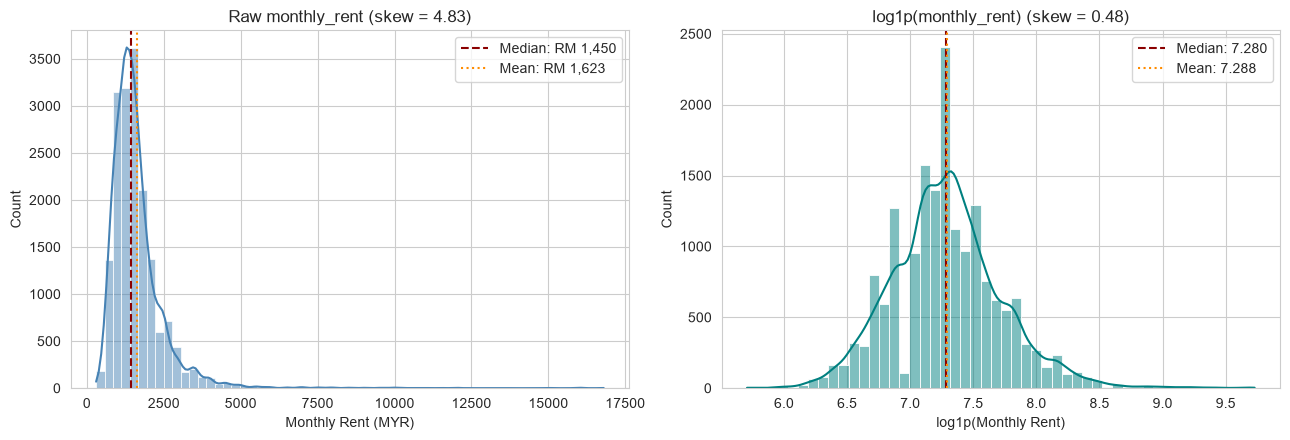

In [8]:
rent_raw = df_clean["monthly_rent"]
rent_log = np.log1p(rent_raw)

target_stats = pd.DataFrame({
    "monthly_rent (MYR)": [
        rent_raw.count(), rent_raw.mean(), rent_raw.std(),
        rent_raw.min(), rent_raw.quantile(0.05), rent_raw.quantile(0.25),
        rent_raw.median(), rent_raw.quantile(0.75), rent_raw.quantile(0.95),
        rent_raw.quantile(0.99), rent_raw.max(), rent_raw.skew(), rent_raw.kurtosis(),
    ],
    "log1p(monthly_rent)": [
        rent_log.count(), rent_log.mean(), rent_log.std(),
        rent_log.min(), rent_log.quantile(0.05), rent_log.quantile(0.25),
        rent_log.median(), rent_log.quantile(0.75), rent_log.quantile(0.95),
        rent_log.quantile(0.99), rent_log.max(), rent_log.skew(), rent_log.kurtosis(),
    ],
}, index=["count", "mean", "std", "min", "p05", "p25", "median", "p75", "p95", "p99", "max", "skew", "kurtosis"])

display(target_stats.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(rent_raw, bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(rent_raw.median(), color="darkred", linestyle="--", label=f"Median: RM {rent_raw.median():,.0f}")
axes[0].axvline(rent_raw.mean(), color="darkorange", linestyle=":", label=f"Mean: RM {rent_raw.mean():,.0f}")
axes[0].set_title(f"Raw monthly_rent (skew = {rent_raw.skew():.2f})")
axes[0].set_xlabel("Monthly Rent (MYR)")
axes[0].legend()

sns.histplot(rent_log, bins=50, kde=True, ax=axes[1], color="teal")
axes[1].axvline(rent_log.median(), color="darkred", linestyle="--", label=f"Median: {rent_log.median():.3f}")
axes[1].axvline(rent_log.mean(), color="darkorange", linestyle=":", label=f"Mean: {rent_log.mean():.3f}")
axes[1].set_title(f"log1p(monthly_rent) (skew = {rent_log.skew():.2f})")
axes[1].set_xlabel("log1p(Monthly Rent)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Findings & Decision (4.1):**
* **Severe right-skew in raw `monthly_rent`:** `mean` (`RM 1,623.33`) sits well above `median` (`RM 1,450.00`; IQR `RM 1,100–1,850`), while `p95` (`RM 3,099`), `p99` (`RM 4,700`), and `max` (`RM 16,800`) create **`skew = 4.834`** and **`kurtosis = 49.118`**.
* **`log1p` transformation validated:** Taking `np.log1p(monthly_rent)` cuts skewness **10×** down to **`0.480`** and kurtosis to **`1.343`**, aligning `mean` (`7.288`) and `median` (`7.280`) into a nearly symmetric bell curve (with visible spikes around round psychological rents like `RM 1,000`, `1,200`, `1,500`, and `2,000`).
* **Decisions:**
  1. Train all models on **`np.log1p(monthly_rent)`** and convert back via `np.expm1` for MYR RMSE evaluation.
  2. Use **median and IQR** (not only mean) in subsequent EDA steps so the top 1% luxury tail doesn't distort group comparisons.
* **Next:** Test **Hypothesis H1**—how strongly `region`, `area`, `furnished`, and `property_type` separate rental tiers.

### 4.2 Testing H1: Location, Furnishing & Property Type Tiers

**Why & How:**
* **Hypothesis H1** predicts that prime Kuala Lumpur districts and *Fully Furnished* units command substantial, non-linear rental premiums over outer Selangor districts and unfurnished units.
* Because `4.1` showed strong right-skew, we summarize each tier by **median and IQR** (`p25–p75`) across `region`, `furnished × region`, `property_type`, and township `area` (`count >= 30` to avoid noisy 1-row extremes), plus side-by-side boxplots/barplots (`showfliers=False`) to check whether furnishing gaps widen across regions (**H3**).

=== 1. REGION ===


,count,p25,median,p75,mean,iqr
region,,,,,,
kuala lumpur,8789,1300.0,1600.0,2200.0,1885.6,900.0
selangor,8812,999.0,1250.0,1600.0,1361.8,601.0



=== 2. FURNISHED x REGION ===


count  median    mean
region       furnished                                 
kuala lumpur fully furnished       4095  2000.0  2359.0
             not furnished         1198  1200.0  1174.1
             partially furnished   3496  1500.0  1574.8
selangor     fully furnished       3287  1550.0  1681.8
             not furnished         1850   900.0   956.2
             partially furnished   3675  1200.0  1279.6


=== 3. PROPERTY TYPE ===


,count,p25,median,p75,mean,iqr
property_type,,,,,,
service residence,4673,1400.0,1700.0,2200.0,1881.1,800.0
condominium,7311,1300.0,1600.0,2000.0,1834.3,700.0
townhouse condo,33,1200.0,1600.0,2500.0,2106.0,1300.0
duplex,73,1399.0,1600.0,1900.0,1863.4,501.0
others,79,925.0,1200.0,1700.0,1466.2,775.0
studio,171,1000.0,1200.0,1400.0,1281.7,400.0
apartment,4720,850.0,1100.0,1300.0,1141.6,450.0
flat,541,700.0,800.0,900.0,817.4,200.0



=== 4. TOP 10 PRICIEST & BOTTOM 10 AFFORDABLE AREAS (count >= 30) ===


,count,p25,median,p75,mean,iqr
area,,,,,,
klcc,266,2399.2,3300.0,4000.0,3940.3,1600.8
mont kiara,274,2600.0,3200.0,3875.0,3528.4,1275.0
bukit bintang,85,2000.0,2500.0,3700.0,2993.5,1700.0
bangsar,45,2000.0,2300.0,3700.0,2750.1,1700.0
titiwangsa,65,2000.0,2299.0,2500.0,2166.2,500.0
sri damansara,58,2000.0,2200.0,2499.8,2281.0,499.8
desa parkcity,46,1900.0,2100.0,2300.0,2357.6,400.0
ara damansara,74,1712.5,2000.0,2475.0,2100.1,762.5
ampang hilir,72,1800.0,2000.0,3275.0,2983.6,1475.0


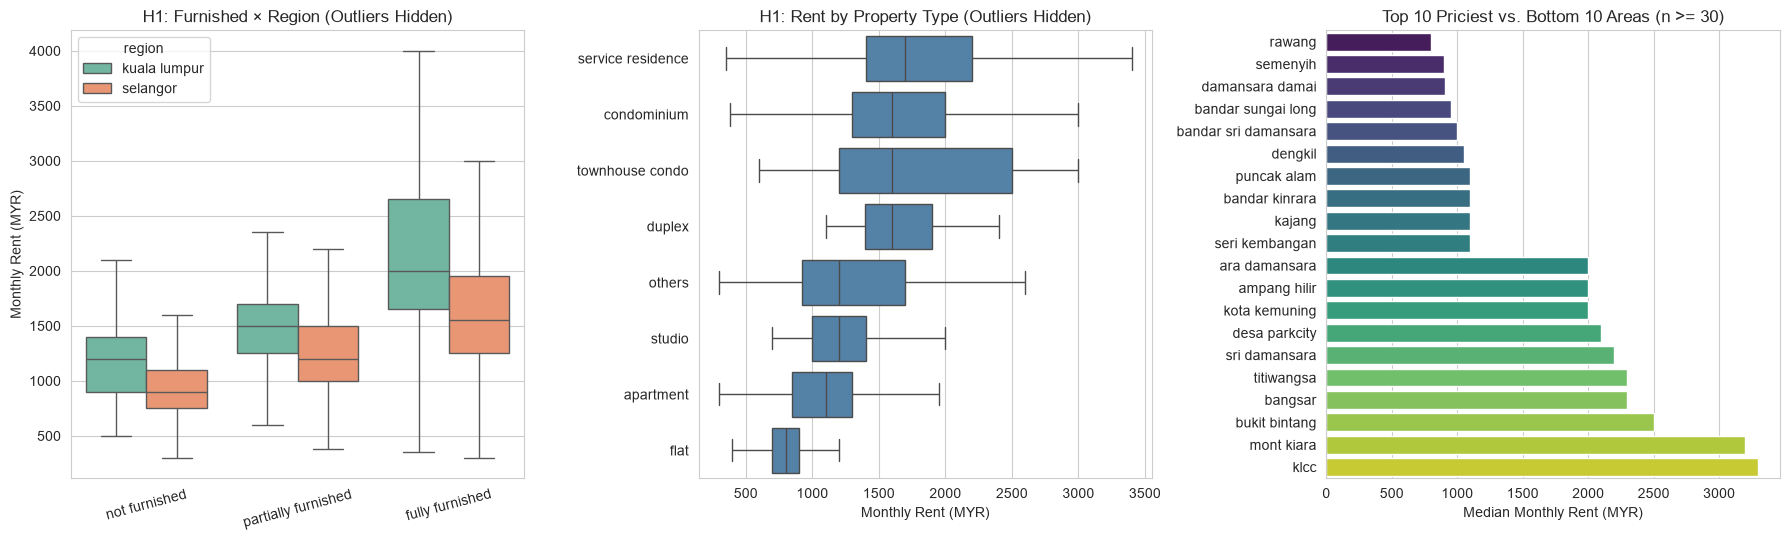

In [9]:
# 1. Group summary helper (median, IQR, mean)
def group_rent_summary(df, col, min_count=1):
    tbl = (
        df.groupby(col)["monthly_rent"]
        .agg(
            count="count",
            p25=lambda s: s.quantile(0.25),
            median="median",
            p75=lambda s: s.quantile(0.75),
            mean="mean",
        )
    )
    tbl["iqr"] = tbl["p75"] - tbl["p25"]
    return tbl[tbl["count"] >= min_count].sort_values("median", ascending=False).round(1)

print("=== 1. REGION ===")
display(group_rent_summary(df_clean, "region"))

print("\n=== 2. FURNISHED x REGION ===")
display(
    df_clean.groupby(["region", "furnished"])["monthly_rent"]
    .agg(count="count", median="median", mean="mean")
    .round(1)
)

print("\n=== 3. PROPERTY TYPE ===")
display(group_rent_summary(df_clean, "property_type"))

print("\n=== 4. TOP 10 PRICIEST & BOTTOM 10 AFFORDABLE AREAS (count >= 30) ===")
area_stats = group_rent_summary(df_clean, "area", min_count=30)
display(pd.concat([area_stats.head(10), area_stats.tail(10)]))

# 2. Visuals for H1 (outliers hidden on boxplots for clear tier comparison)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

furn_order = ["not furnished", "partially furnished", "fully furnished"]
sns.boxplot(
    data=df_clean, x="furnished", y="monthly_rent", hue="region",
    order=furn_order, showfliers=False, ax=axes[0], palette="Set2"
)
axes[0].set_title("H1: Furnished × Region (Outliers Hidden)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Monthly Rent (MYR)")
axes[0].tick_params(axis="x", rotation=15)

prop_order = group_rent_summary(df_clean, "property_type").index.tolist()
sns.boxplot(
    data=df_clean, y="property_type", x="monthly_rent",
    order=prop_order, showfliers=False, ax=axes[1], color="steelblue"
)
axes[1].set_title("H1: Rent by Property Type (Outliers Hidden)")
axes[1].set_xlabel("Monthly Rent (MYR)")
axes[1].set_ylabel("")

top_bot_areas = pd.concat([area_stats.head(10), area_stats.tail(10)]).sort_values("median")
sns.barplot(
    x=top_bot_areas["median"], y=top_bot_areas.index,
    ax=axes[2], palette="viridis", hue=top_bot_areas.index, legend=False
)
axes[2].set_title("Top 10 Priciest vs. Bottom 10 Areas (n >= 30)")
axes[2].set_xlabel("Median Monthly Rent (MYR)")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

**Findings (4.2):**
* **Strong regional & furnishing tiers (H1 confirmed):** `kuala lumpur` (`n = 8,789`) rents at **`RM 1,600` median** (`mean RM 1,885.6`, `IQR 900`) vs. `selangor` (`n = 8,812`) at **`RM 1,250` median** (`mean RM 1,361.8`, `IQR 601`). Within both regions, rent climbs monotonically from `not furnished` (`RM 1,200` KL / `RM 900` Selangor) → `partially furnished` (`RM 1,500` / `RM 1,200`) → `fully furnished` (`RM 2,000` / `RM 1,550`).
* **Non-linear / multiplicative gap (supports H3):** Moving from `not furnished` to `fully furnished` adds **`+RM 800` median (`+RM 1,184.9` mean)** in Kuala Lumpur vs. **`+RM 650` median (`+RM 725.6` mean)** in Selangor, and the KL `fully furnished` box stretches much higher (`p75 ~ RM 2,650`, upper whisker `RM 4,000`).
* **Clear `property_type` hierarchy:** `service residence` (`RM 1,700`) and `condominium`/`duplex`/`townhouse condo` (`RM 1,600`) lead `studio`/`others` (`RM 1,200`), `apartment` (`RM 1,100`), and `flat` (`RM 800`, tight `IQR 200`).
* **`4.1×` township spread beyond `region`:** Among areas with `n >= 30`, medians span from **`rawang` (`RM 800`)** and **`semenyih` (`RM 900`)** up to **`mont kiara` (`RM 3,200`)** and **`klcc` (`RM 3,300`, `mean RM 3,940.3`)**.
* **Next:** Test **Hypothesis H2**—whether rail proximity (`near_rail`) and unit/condo amenities still add value *after* controlling for `property_type` and `furnished` status.

### 4.3 Testing H2: Transit & Amenity Value-Add (Raw vs. Controlled Check)

**Why & How:**
* **Hypothesis H2** states that rail transit access (`near_rail`) and condo/unit amenities add measurable rental value.
* Because raw amenity comparisons can be confounded by property type (`Condominium` vs. `Flat`) and furnishing (`Fully` vs. `Not`), we compare **overall median rent lift** against a **controlled within-tier subset** (`condominium` + `partially furnished`), inspect `near_rail × region` to check for Simpson's Paradox, and plot rent across `facility_count` tiers.

Controlled subset (condominium + partially furnished): 3024 rows


,feature,pct_overall,raw_med_0,raw_med_1,raw_diff,ctrl_med_0,ctrl_med_1,ctrl_diff
0,has_pool,70.2,1100.0,1599.0,499.0,1400.0,1500.0,100.0
1,has_gym,61.8,1200.0,1600.0,400.0,1400.0,1500.0,100.0
3,has_sauna,32.0,1300.0,1700.0,400.0,1400.0,1500.0,100.0
6,has_aircond,54.8,1200.0,1600.0,400.0,1400.0,1500.0,100.0
7,has_washer,37.8,1300.0,1700.0,400.0,1400.0,1500.0,100.0
2,has_security,81.4,1100.0,1500.0,400.0,1450.0,1500.0,50.0
9,has_internet,12.2,1400.0,1600.0,200.0,1499.0,1500.0,1.0
4,has_lift,58.6,1300.0,1500.0,200.0,1499.0,1500.0,1.0
5,near_rail,37.7,1400.0,1500.0,100.0,1500.0,1450.0,-50.0
8,cooking_allowed,65.0,1400.0,1500.0,100.0,1500.0,1450.0,-50.0



=== near_rail × region (overall vs. controlled condo tier) ===


count  median    mean
region       near_rail                       
kuala lumpur 0           4957  1600.0  1846.3
             1           3832  1700.0  1936.4
selangor     0           6008  1200.0  1339.0
             1           2804  1300.0  1410.5

count  median    mean
region       near_rail                       
kuala lumpur 0           1010  1500.0  1712.2
             1            644  1526.0  1711.4
selangor     0            940  1300.0  1450.2
             1            430  1300.0  1359.4


=== facility_count tiers ===


,count,median,mean
facility_count,,,
0,1921,1300.0,1419.7
1-4,2794,1000.0,1185.0
5-8,6262,1450.0,1618.7
9-11,4303,1600.0,1855.0
12-14,2321,1699.0,1902.4


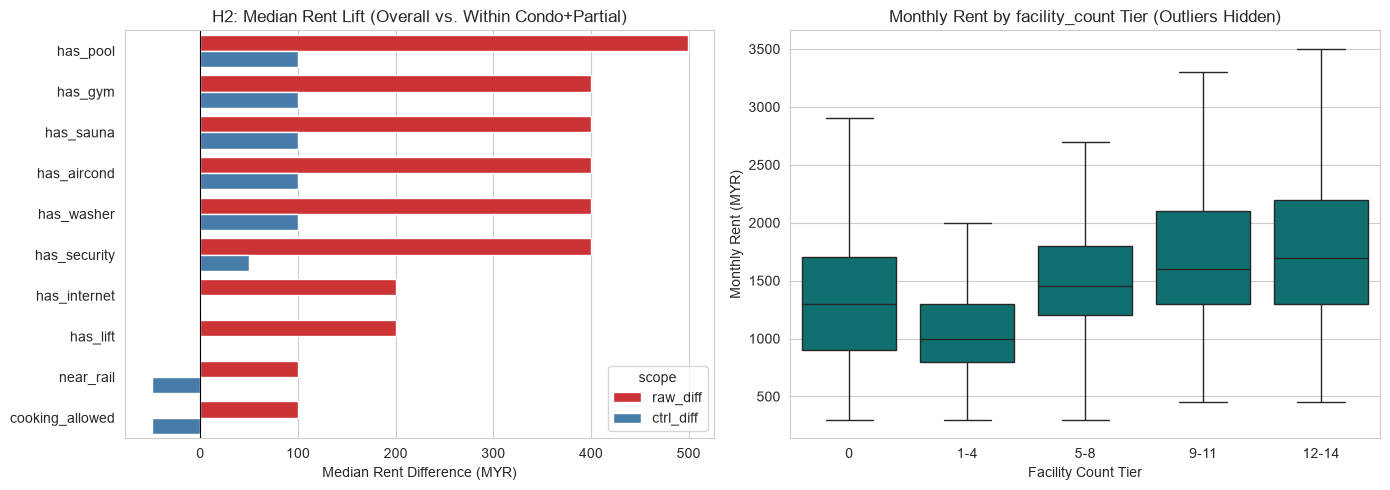

In [10]:
amenity_cols = [
    "has_pool", "has_gym", "has_security", "has_sauna", "has_lift",
    "near_rail", "has_aircond", "has_washer", "cooking_allowed", "has_internet"
]

# 1. Raw vs. Controlled (Condominium + Partially Furnished) amenity lift
ctrl_mask = (df_clean["property_type"] == "condominium") & (df_clean["furnished"] == "partially furnished")
df_ctrl = df_clean[ctrl_mask]
print(f"Controlled subset (condominium + partially furnished): {len(df_ctrl)} rows")

h2_rows = []
for col in amenity_cols:
    m_all = df_clean[col] == 1
    m_ctrl = df_ctrl[col] == 1
    h2_rows.append({
        "feature": col,
        "pct_overall": round(m_all.mean() * 100, 1),
        "raw_med_0": df_clean.loc[~m_all, "monthly_rent"].median(),
        "raw_med_1": df_clean.loc[m_all, "monthly_rent"].median(),
        "raw_diff": df_clean.loc[m_all, "monthly_rent"].median() - df_clean.loc[~m_all, "monthly_rent"].median(),
        "ctrl_med_0": df_ctrl.loc[~m_ctrl, "monthly_rent"].median(),
        "ctrl_med_1": df_ctrl.loc[m_ctrl, "monthly_rent"].median(),
        "ctrl_diff": df_ctrl.loc[m_ctrl, "monthly_rent"].median() - df_ctrl.loc[~m_ctrl, "monthly_rent"].median(),
    })

h2_df = pd.DataFrame(h2_rows).sort_values("ctrl_diff", ascending=False)
display(h2_df)

# 2. Check near_rail by region (overall and within controlled condo tier)
print("\n=== near_rail × region (overall vs. controlled condo tier) ===")
display(
    df_clean.groupby(["region", "near_rail"])["monthly_rent"]
    .agg(["count", "median", "mean"])
    .round(1)
)
display(
    df_ctrl.groupby(["region", "near_rail"])["monthly_rent"]
    .agg(["count", "median", "mean"])
    .round(1)
)

# 3. facility_count tiers & H2 visuals
fac_bins = pd.cut(df_clean["facility_count"], bins=[-1, 0, 4, 8, 11, 14], labels=["0", "1-4", "5-8", "9-11", "12-14"])
fac_summary = df_clean.groupby(fac_bins, observed=False)["monthly_rent"].agg(["count", "median", "mean"]).round(1)
print("\n=== facility_count tiers ===")
display(fac_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

h2_plot = h2_df.melt(id_vars="feature", value_vars=["raw_diff", "ctrl_diff"], var_name="scope", value_name="median_diff")
sns.barplot(data=h2_plot, y="feature", x="median_diff", hue="scope", ax=axes[0], palette="Set1")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("H2: Median Rent Lift (Overall vs. Within Condo+Partial)")
axes[0].set_xlabel("Median Rent Difference (MYR)")
axes[0].set_ylabel("")

sns.boxplot(
    data=df_clean.assign(fac_bin=fac_bins),
    x="fac_bin", y="monthly_rent", showfliers=False, ax=axes[1], color="teal"
)
axes[1].set_title("Monthly Rent by facility_count Tier (Outliers Hidden)")
axes[1].set_xlabel("Facility Count Tier")
axes[1].set_ylabel("Monthly Rent (MYR)")

plt.tight_layout()
plt.show()

**Findings (4.3):**
* **Confounding exposed — H2 is partially supported:** Globally, amenities look huge (`has_pool +RM 499`, `has_gym/has_sauna/has_aircond/has_washer/has_security +RM 400`). Once we hold building type and furnishing constant (`condominium` + `partially furnished`, `n = 3,024`), **`has_pool`**, **`has_gym`**, **`has_sauna`**, **`has_aircond`**, and **`has_washer`** each retain a real **`+RM 100`** median premium (and `has_security` **`+RM 50`**), whereas `has_lift` and `has_internet` shrink to `+RM 1` inside condos.
* **Nuanced `near_rail` effect (car-centric luxury confounding):** Overall, `near_rail == 1` commands **`+RM 100`** median lift in **both** KL (`RM 1,700` vs. `1,600`) and Selangor (`RM 1,300` vs. `1,200`). Inside the controlled condo subset, however, the gap shrinks (`+RM 26` KL, `RM 0` Selangor; `-RM 50` pooled) because affluent car-centric enclaves (`Mont Kiara`, `Desa ParkCity`) often lack rail links while older commuter condos sit near KTM/LRT lines.
* **Non-linear U-shape at `facility_count == 0` (supports H3):** Median rent drops from **`RM 1,300` at `0` facilities** (`n = 1,921`, undisclosed/blank `facilities` field) down to **`RM 1,000` at `1–4` facilities** (basic flats/apartments), then climbs steadily to **`RM 1,450` (`5–8`) → `RM 1,600` (`9–11`) → `RM 1,699` (`12–14`)**. Tree ensembles can split `facility_count == 0` naturally, whereas a linear model struggles with that dip.
* **Next:** Inspect numeric relationships (`size_sqft`, `rooms_num`, `bathroom_num`, `parking_num`, `completion_year_num`) and feature collinearity before locking the train/validation/test split.

### 4.4 Numeric Relationships, Building Age & Collinearity

**Why & How:**
* Before splitting the data for modeling, we measure Pearson and Spearman correlations between all numeric features and both `monthly_rent` and `log1p(monthly_rent)`.
* We also inspect a numeric correlation heatmap for multicollinearity clusters (which affect `Ridge` weights) and plot `size_sqft × region`, `parking_num`, and `completion_year_num` (on the `9,382` disclosed rows) to check for non-linear slopes (**H3**).

=== Numeric Feature Correlations with Rent ===


,pearson_raw,pearson_log1p,spearman_rent
size_sqft,0.567,0.514,0.449
bathroom_num,0.399,0.349,0.265
facility_count,0.239,0.331,0.354
has_completion_year,0.194,0.282,0.305
parking_num,0.226,0.277,0.272
has_parking_info,0.116,0.181,0.180
completion_year_num,0.077,0.126,0.163
rooms_num,0.141,0.104,0.066


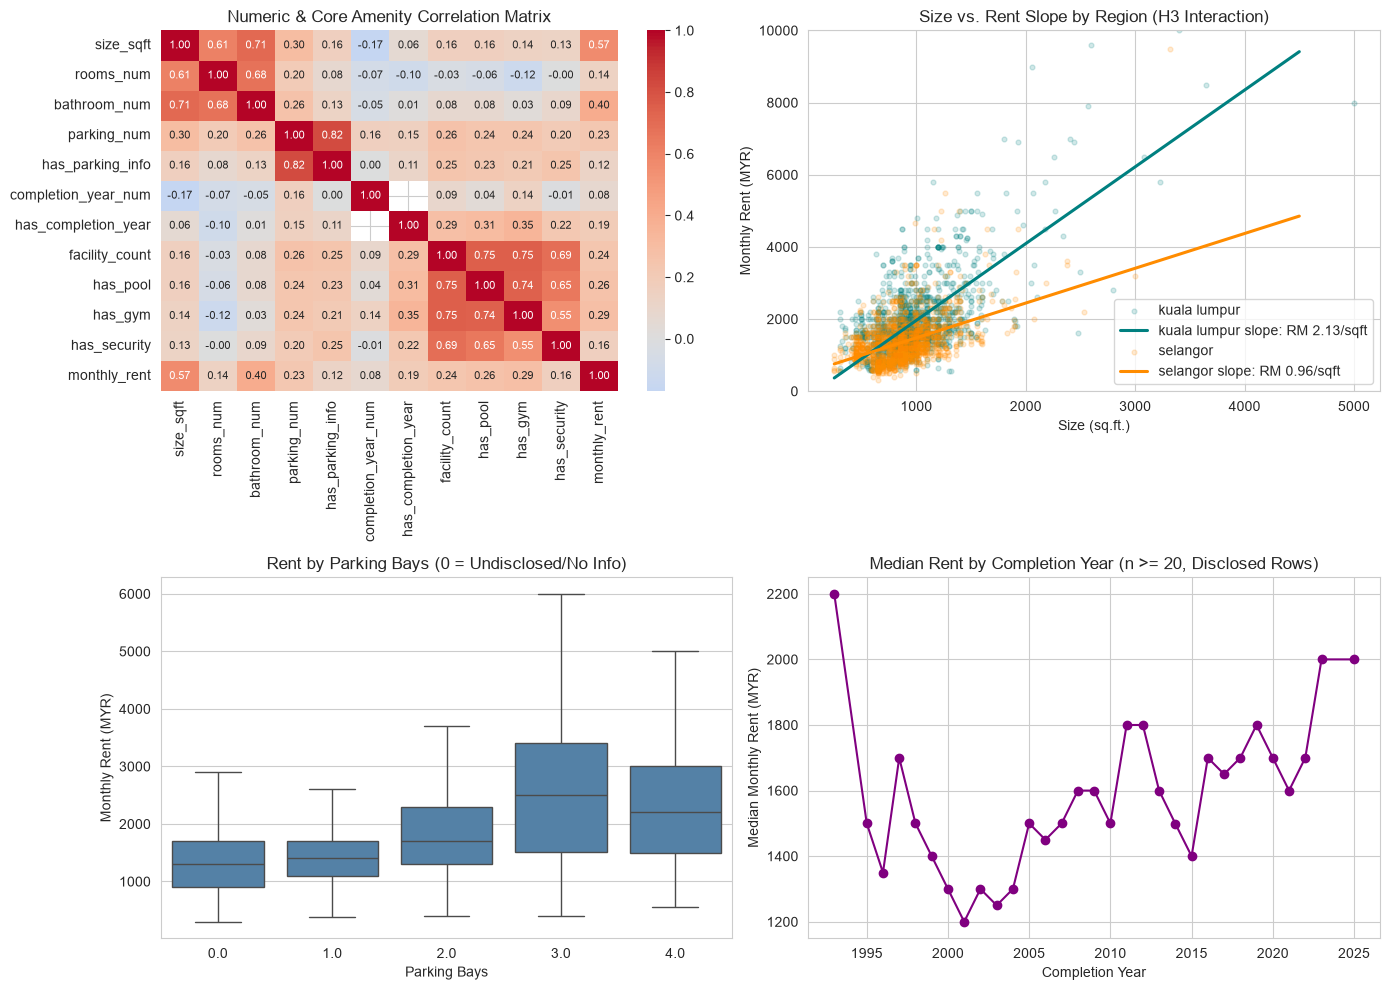

In [11]:
num_cols = [
    "size_sqft", "rooms_num", "bathroom_num", "parking_num",
    "has_parking_info", "completion_year_num", "has_completion_year", "facility_count"
]

# 1. Pearson & Spearman correlation with raw vs. log1p rent
df_corr = df_clean[num_cols + ["monthly_rent"]].copy()
df_corr["log1p_rent"] = np.log1p(df_corr["monthly_rent"])

corr_summary = pd.DataFrame({
    "pearson_raw": df_corr.corr(method="pearson")["monthly_rent"].drop(["monthly_rent", "log1p_rent"]),
    "pearson_log1p": df_corr.corr(method="pearson")["log1p_rent"].drop(["monthly_rent", "log1p_rent"]),
    "spearman_rent": df_corr.corr(method="spearman")["monthly_rent"].drop(["monthly_rent", "log1p_rent"]),
}).sort_values("pearson_log1p", ascending=False).round(3)

print("=== Numeric Feature Correlations with Rent ===")
display(corr_summary)

# 2. Visuals: Correlation heatmap + size_sqft x region + parking + completion_year
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Heatmap
corr_mat = df_clean[num_cols + ["has_pool", "has_gym", "has_security", "monthly_rent"]].corr().round(2)
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0, 0], annot_kws={"size": 8})
axes[0, 0].set_title("Numeric & Core Amenity Correlation Matrix")

# size_sqft vs monthly_rent by region (sample 3,000 points for clarity + linear fit lines)
sample_df = df_clean.sample(3000, random_state=42)
for reg, color in [("kuala lumpur", "teal"), ("selangor", "darkorange")]:
    sub = sample_df[sample_df["region"] == reg]
    axes[0, 1].scatter(sub["size_sqft"], sub["monthly_rent"], alpha=0.18, s=12, color=color, label=reg)
    m, b = np.polyfit(df_clean.loc[df_clean["region"] == reg, "size_sqft"],
                      df_clean.loc[df_clean["region"] == reg, "monthly_rent"], 1)
    xs = np.array([250, 4500])
    axes[0, 1].plot(xs, m * xs + b, color=color, linewidth=2.2, label=f"{reg} slope: RM {m:.2f}/sqft")
axes[0, 1].set_ylim(0, 10000)
axes[0, 1].set_title("Size vs. Rent Slope by Region (H3 Interaction)")
axes[0, 1].set_xlabel("Size (sq.ft.)")
axes[0, 1].set_ylabel("Monthly Rent (MYR)")
axes[0, 1].legend()

# parking_num
sns.boxplot(
    data=df_clean, x="parking_num", y="monthly_rent",
    showfliers=False, ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set_title("Rent by Parking Bays (0 = Undisclosed/No Info)")
axes[1, 0].set_xlabel("Parking Bays")
axes[1, 0].set_ylabel("Monthly Rent (MYR)")

# completion_year_num median trend (disclosed rows only, n >= 20)
yr_df = df_clean.dropna(subset=["completion_year_num"]).copy()
yr_df = yr_df[yr_df["completion_year_num"] >= 1990]
yr_trend = yr_df.groupby("completion_year_num")["monthly_rent"].agg(["count", "median"])
yr_trend = yr_trend[yr_trend["count"] >= 20]
axes[1, 1].plot(yr_trend.index, yr_trend["median"], marker="o", color="purple")
axes[1, 1].set_title("Median Rent by Completion Year (n >= 20, Disclosed Rows)")
axes[1, 1].set_xlabel("Completion Year")
axes[1, 1].set_ylabel("Median Monthly Rent (MYR)")

plt.tight_layout()
plt.show()

**Findings (4.4):**
* **Strongest numeric predictors & log1p confirmation:** `size_sqft` leads (`pearson_raw = 0.567`, `pearson_log1p = 0.514`, `spearman = 0.449`), followed by `bathroom_num` (`0.399` / `0.349`), `facility_count` (`0.239` / `0.331` / `spearman 0.354`), `has_completion_year` (`0.194` / `0.282`), and `parking_num` (`0.226` / `0.277`). Notice `facility_count`, `has_completion_year`, `parking_num`, `has_parking_info`, and `completion_year_num` all correlate **noticeably stronger with `log1p(monthly_rent)`** than raw rent, reinforcing our `4.1` transform choice. Meanwhile, `rooms_num` has weak linear correlation (`0.141` raw / `0.066` Spearman) because 3-bedroom low-cost flats rent for far less than 1-bedroom KLCC luxury studios.
* **2.2× steeper size slope in KL (direct H3 interaction):** In the `Size vs. Rent` scatter, `kuala lumpur` climbs at **`RM 2.13 / sq.ft.`** vs. `selangor` at **`RM 0.96 / sq.ft.`**. A single linear slope for `size_sqft` cannot capture that regional multiplier without explicit interaction terms, whereas tree ensembles split `region/area × size_sqft` natively.
* **Multicollinearity clusters (justifies L2 regularization):** The heatmap shows expected collinearity between `size_sqft` and `bathroom_num` (`r = 0.71`), `rooms_num` and `bathroom_num` (`r = 0.68`), `parking_num` and `has_parking_info` (`r = 0.82`), and `facility_count` with `has_pool`/`has_gym`/`has_security` (`r = 0.69–0.75`). This confirms `Ridge` (L2 regularization + numeric scaling) is needed over unregularized OLS.
* **Non-linear U-shape in `completion_year_num` (disclosed rows):** Early 1990s condos show high medians (`RM 2,200` near `1993`, driven by larger legacy condos—`size_sqft` correlates `-0.17` with `completion_year_num`), dipping to `RM 1,200–1,300` around `2000–2004`, then rising steadily to `RM 2,000` for `2023–2025` developments.

### 4.5 EDA Summary & Modeling Implications
* **H1 (Confirmed):** `region`, `area` (`4.1×` spread across `n >= 30` townships), `property_type`, and `furnished` tiers drive primary rental separation, with widening KL vs. Selangor gaps.
* **H2 (Partially Supported):** Condo/unit amenities (`has_pool`, `has_gym`, `has_sauna`, `has_aircond`, `has_washer`, `has_security`) keep `+RM 50–100` median lift even within `condominium + partially furnished`, while `near_rail` (`+RM 100` overall) attenuates within condos due to affluent car-centric suburbs (`Mont Kiara`, `Desa ParkCity`).
* **H3 (Motivated):** Diverging regional size slopes (`RM 2.13` vs `0.96 / sq.ft.`), the U-shaped `facility_count == 0` dip, and non-linear `completion_year` curve strongly favor tree ensembles (`RandomForest`, `XGBoost`) over `Ridge`.
* **Next:** Split `df_clean` (`60/20/20`) and fit our leakage-free preprocessor (`top_50_areas`, `completion_year` median, `DictVectorizer`) strictly on `df_train`.

## 5. Train / Validation / Test Split & Leakage-Free Preprocessing

**Why & How:**
* We split `df_clean` (`17,601` rows) into **60% train / 20% validation / 20% test** stratified by deciles of `log1p(monthly_rent)` so the luxury upper tail (`p95–max`) is evenly represented across all three splits.
* We then fit `top_50_areas` and `completion_year_num` median **strictly on `df_train`**, transform all splits to eliminate remaining nulls without leakage, vectorize features with `DictVectorizer(sparse=False)`, and define our evaluation helper (`rmse_myr` via `np.expm1`).

In [12]:
# 1. Stratified 60/20/20 split using deciles of log1p(monthly_rent)
rent_bins = pd.qcut(np.log1p(df_clean["monthly_rent"]), q=10, labels=False)

df_full_train, df_test = train_test_split(
    df_clean, test_size=0.20, random_state=42, stratify=rent_bins
)
full_train_bins = pd.qcut(np.log1p(df_full_train["monthly_rent"]), q=10, labels=False)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42, stratify=full_train_bins  # 0.25 * 0.80 = 0.20
)

for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(
        f"{name:5s}: n={len(part):5d} ({len(part)/len(df_clean):.1%}) | "
        f"KL={ (part['region']=='kuala lumpur').mean():.1%} | "
        f"med=RM {part['monthly_rent'].median():,.0f} | "
        f"mean=RM {part['monthly_rent'].mean():,.1f} | "
        f"p99=RM {part['monthly_rent'].quantile(0.99):,.0f}"
    )

# 2. Leakage-free preprocessor fit ONLY on df_train
def fit_preprocessor(train_df, top_n_areas=50):
    top_areas = train_df["area"].value_counts().head(top_n_areas).index.tolist()
    year_median = float(train_df["completion_year_num"].median())
    return {"top_areas": set(top_areas), "top_areas_list": top_areas, "year_median": year_median}

def transform_features(df, prep, feature_cols):
    out = df[feature_cols].copy()
    out["area"] = out["area"].where(out["area"].isin(prep["top_areas"]), "other")
    out["completion_year_num"] = out["completion_year_num"].fillna(prep["year_median"])
    return out

feature_cols = [c for c in df_clean.columns if c != "monthly_rent"]
prep_artifacts = fit_preprocessor(df_train, top_n_areas=50)
print(f"\nFit on df_train -> top_areas: {len(prep_artifacts['top_areas_list'])}, year_median: {prep_artifacts['year_median']}")

X_train_df = transform_features(df_train, prep_artifacts, feature_cols)
X_val_df = transform_features(df_val, prep_artifacts, feature_cols)
X_test_df = transform_features(df_test, prep_artifacts, feature_cols)

print("Remaining nulls (train / val / test):",
      X_train_df.isnull().sum().sum(),
      X_val_df.isnull().sum().sum(),
      X_test_df.isnull().sum().sum())

# 3. Vectorize with DictVectorizer & prepare log1p targets
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(X_train_df.to_dict(orient="records"))
X_val = dv.transform(X_val_df.to_dict(orient="records"))
X_test = dv.transform(X_test_df.to_dict(orient="records"))

y_train_raw = df_train["monthly_rent"].values
y_val_raw = df_val["monthly_rent"].values
y_test_raw = df_test["monthly_rent"].values

y_train = np.log1p(y_train_raw)
y_val = np.log1p(y_val_raw)
y_test = np.log1p(y_test_raw)

def rmse_myr(y_true_raw, y_pred_log):
    y_pred_raw = np.clip(np.expm1(y_pred_log), a_min=0.0, a_max=None)
    return root_mean_squared_error(y_true_raw, y_pred_raw)

print(f"Vectorized shapes -> X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")

train: n=10560 (60.0%) | KL=50.4% | med=RM 1,450 | mean=RM 1,620.1 | p99=RM 4,600
val  : n= 3520 (20.0%) | KL=49.3% | med=RM 1,450 | mean=RM 1,616.8 | p99=RM 4,700
test : n= 3521 (20.0%) | KL=49.2% | med=RM 1,450 | mean=RM 1,639.4 | p99=RM 5,000

Fit on df_train -> top_areas: 50, year_median: 2017.0
Remaining nulls (train / val / test): 0 0 0
Vectorized shapes -> X_train: (10560, 81), X_val: (3520, 81), X_test: (3521, 81)


**Findings (5):**
* **Balanced stratified 60/20/20 split:** `df_train` (`10,560`), `df_val` (`3,520`), and `df_test` (`3,521`) share identical medians (`RM 1,450`), nearly identical `KL` proportions (`49.2%–50.4%`), and tightly matched means (`RM 1,616.8–1,639.4`) and `p99` tails (`RM 4,600–5,000`).
* **Zero nulls & zero leakage:** Fitting `top_areas` (`50`) and `year_median` (`2017.0`) strictly on `df_train` eliminates all remaining `completion_year_num` nulls (`0 / 0 / 0`) and produces **`81` vectorized features** via `DictVectorizer`.
* **Next:** Establish a naive `Dummy` floor and tune our regularized linear baseline (`Ridge` + `StandardScaler`) in Section 6.1.

## 6. Model Training, Tuning & Hypothesis H3 Evaluation

### 6.1 Baseline Models: Dummy Regressor & Tuned Ridge Regression

**Why & How:**
* We first compute a `DummyRegressor(strategy="median")` sanity floor on `val`, then tune a regularized linear baseline (`StandardScaler` + `Ridge`) across `alpha` values from `0.1` to `500.0`.
* Scaling puts continuous (`size_sqft`, `completion_year_num`), count, and one-hot features on unit variance so L2 regularization penalizes correlated features (`4.4`) evenly. All models train on `log1p(monthly_rent)` and are evaluated on original MYR via `rmse_myr` and MAE.

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

def eval_predictions(y_true_raw, y_true_log, y_pred_log):
    y_pred_raw = np.clip(np.expm1(y_pred_log), a_min=0.0, a_max=None)
    return {
        "rmse_myr": root_mean_squared_error(y_true_raw, y_pred_raw),
        "mae_myr": mean_absolute_error(y_true_raw, y_pred_raw),
        "rmse_log": root_mean_squared_error(y_true_log, y_pred_log),
    }

# 1. Naive Dummy floor
dummy = DummyRegressor(strategy="median")
dummy.fit(X_train, y_train)
dummy_val = eval_predictions(y_val_raw, y_val, dummy.predict(X_val))
print(
    f"Dummy Baseline (median) -> Val RMSE: RM {dummy_val['rmse_myr']:,.2f} | "
    f"Val MAE: RM {dummy_val['mae_myr']:,.2f} | Val Log-RMSE: {dummy_val['rmse_log']:.4f}\n"
)

# 2. Tune Ridge alpha with StandardScaler
alphas = [0.1, 1.0, 5.0, 10.0, 25.0, 50.0, 100.0, 200.0, 500.0]
ridge_results = []
for a in alphas:
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=a, random_state=42))
    pipe.fit(X_train, y_train)
    tr_m = eval_predictions(y_train_raw, y_train, pipe.predict(X_train))
    va_m = eval_predictions(y_val_raw, y_val, pipe.predict(X_val))
    ridge_results.append({
        "alpha": a,
        "train_rmse_myr": tr_m["rmse_myr"],
        "val_rmse_myr": va_m["rmse_myr"],
        "val_mae_myr": va_m["mae_myr"],
        "val_rmse_log": va_m["rmse_log"],
    })

ridge_df = pd.DataFrame(ridge_results).round(3)
display(ridge_df)

best_alpha = ridge_df.loc[ridge_df["val_rmse_myr"].idxmin(), "alpha"]
best_ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha, random_state=42))
best_ridge.fit(X_train, y_train)
ridge_val_metrics = eval_predictions(y_val_raw, y_val, best_ridge.predict(X_val))

print(
    f"\nBest Ridge (alpha={best_alpha}) -> Val RMSE: RM {ridge_val_metrics['rmse_myr']:,.2f} | "
    f"Val MAE: RM {ridge_val_metrics['mae_myr']:,.2f} | Val Log-RMSE: {ridge_val_metrics['rmse_log']:.4f}"
)

# Inspect top positive/negative standardized Ridge coefficients
coef_s = pd.Series(best_ridge.named_steps["ridge"].coef_, index=dv.get_feature_names_out())
print("\nTop 10 positive Ridge weights:")
print(coef_s.sort_values(ascending=False).head(10).round(4))
print("\nTop 10 negative Ridge weights:")
print(coef_s.sort_values(ascending=True).head(10).round(4))

Dummy Baseline (median) -> Val RMSE: RM 907.29 | Val MAE: RM 542.07 | Val Log-RMSE: 0.4354



,alpha,train_rmse_myr,val_rmse_myr,val_mae_myr,val_rmse_log
0,0.1,468.456,469.874,281.668,0.223
1,1.0,468.449,469.859,281.666,0.223
2,5.0,468.418,469.796,281.659,0.223
3,10.0,468.380,469.719,281.650,0.223
4,25.0,468.273,469.495,281.623,0.223
5,50.0,468.114,469.151,281.582,0.223
6,100.0,467.870,468.560,281.521,0.223
7,200.0,467.643,467.733,281.430,0.223
8,500.0,468.572,467.429,281.433,0.224



Best Ridge (alpha=500.0) -> Val RMSE: RM 467.43 | Val MAE: RM 281.43 | Val Log-RMSE: 0.2237

Top 10 positive Ridge weights:
size_sqft                          0.1489
furnished=fully furnished          0.0750
area=klcc                          0.0488
completion_year_num                0.0486
area=mont kiara                    0.0485
bathroom_num                       0.0460
property_type=service residence    0.0455
parking_num                        0.0403
has_completion_year                0.0397
region=kuala lumpur                0.0380
dtype: float64

Top 10 negative Ridge weights:
furnished=not furnished         -0.0633
property_type=apartment         -0.0401
region=selangor                 -0.0380
area=kajang                     -0.0378
property_type=flat              -0.0378
area=semenyih                   -0.0342
furnished=partially furnished   -0.0269
area=kepong                     -0.0248
area=seri kembangan             -0.0247
cooking_allowed                 -0.0241
dtype: f

**Findings (6.1):**
* **Ridge cuts error nearly in half vs. Dummy:** `DummyRegressor(median)` scores **`RM 907.29` Val RMSE** (`RM 542.07` MAE, `0.4354` Log-RMSE), while tuned `Ridge(alpha=500.0)` achieves **`RM 467.43` Val RMSE** (`RM 281.43` MAE, `0.2237` Log-RMSE).
* **Bias-limited (underfitting) linear ceiling:** Notice `train_rmse_myr` (`RM 468.57`) and `val_rmse_myr` (`RM 467.43`) sit practically on top of each other—`Ridge` is not overfitting, it is limited by linear additivity (unable to model KL vs. Selangor size slopes, `facility_count == 0` U-shape, or building-era curves).
* **Sensible real-estate weights:** Top positive drivers are `size_sqft` (`+0.1489`), `fully furnished` (`+0.0750`), `klcc` (`+0.0488`), `completion_year_num` (`+0.0486`), and `mont kiara` (`+0.0485`), while `not furnished` (`-0.0633`), `apartment` (`-0.0401`), `selangor` (`-0.0380`), `kajang` (`-0.0378`), and `flat` (`-0.0378`) pull rents down.
* **Next:** Train and tune a non-linear bagging ensemble (`RandomForestRegressor`) to test whether capturing interactions breaks past the `RM 467.43` linear ceiling (**H3**).

### 6.2 Random Forest Regressor Tuning

**Why & How:**
* Unlike `Ridge`, `RandomForestRegressor` models non-linear feature interactions (e.g., `region × size_sqft`, `facility_count == 0` dip, and `completion_year_num` non-linearity) natively via ensembles of decision trees.
* We run a structured two-stage search on `val`: (1) tune `max_depth` and `min_samples_leaf` (`n_estimators=150`) to control overfitting, then (2) tune `max_features` and increase to `n_estimators=300` for stability.

In [14]:
# Stage 1: Tune max_depth and min_samples_leaf
rf_stage1 = []
for depth in [12, 16, 20, None]:
    for leaf in [1, 3, 5, 10]:
        rf = RandomForestRegressor(
            n_estimators=150,
            max_depth=depth,
            min_samples_leaf=leaf,
            max_features=0.7,
            n_jobs=-1,
            random_state=42,
        )
        rf.fit(X_train, y_train)
        tr_m = eval_predictions(y_train_raw, y_train, rf.predict(X_train))
        va_m = eval_predictions(y_val_raw, y_val, rf.predict(X_val))
        rf_stage1.append({
            "max_depth": str(depth),
            "min_samples_leaf": leaf,
            "train_rmse_myr": tr_m["rmse_myr"],
            "val_rmse_myr": va_m["rmse_myr"],
            "val_mae_myr": va_m["mae_myr"],
            "val_rmse_log": va_m["rmse_log"],
        })

rf_s1_df = pd.DataFrame(rf_stage1).sort_values("val_rmse_myr").round(3)
print("=== RF Stage 1: Top 8 (max_depth × min_samples_leaf) ===")
display(rf_s1_df.head(8))

best_row = rf_s1_df.iloc[0]
best_depth = None if best_row["max_depth"] == "None" else int(best_row["max_depth"])
best_leaf = int(best_row["min_samples_leaf"])

# Stage 2: Tune max_features at best depth/leaf
rf_stage2 = []
for mf in [0.4, 0.6, 0.7, 0.85, 1.0]:
    rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        max_features=mf,
        n_jobs=-1,
        random_state=42,
    )
    rf.fit(X_train, y_train)
    va_m = eval_predictions(y_val_raw, y_val, rf.predict(X_val))
    rf_stage2.append({
        "max_features": mf,
        "val_rmse_myr": va_m["rmse_myr"],
        "val_mae_myr": va_m["mae_myr"],
        "val_rmse_log": va_m["rmse_log"],
    })

rf_s2_df = pd.DataFrame(rf_stage2).sort_values("val_rmse_myr").round(3)
print("\n=== RF Stage 2: max_features Sweep ===")
display(rf_s2_df)

best_mf = float(rf_s2_df.iloc[0]["max_features"])

# Final tuned RandomForest with n_estimators=300
best_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    max_features=best_mf,
    n_jobs=-1,
    random_state=42,
)
best_rf.fit(X_train, y_train)
rf_val_metrics = eval_predictions(y_val_raw, y_val, best_rf.predict(X_val))
print(
    f"\nBest RandomForest (depth={best_depth}, leaf={best_leaf}, max_features={best_mf}, n=300) -> "
    f"Val RMSE: RM {rf_val_metrics['rmse_myr']:,.2f} | "
    f"Val MAE: RM {rf_val_metrics['mae_myr']:,.2f} | "
    f"Val Log-RMSE: {rf_val_metrics['rmse_log']:.4f}"
)

=== RF Stage 1: Top 8 (max_depth × min_samples_leaf) ===


,max_depth,min_samples_leaf,train_rmse_myr,val_rmse_myr,val_mae_myr,val_rmse_log
8,20,1,196.217,427.961,231.302,0.195
12,None,1,174.716,429.871,229.895,0.194
4,16,1,233.130,432.897,238.867,0.199
13,None,3,296.433,444.236,239.497,0.199
9,20,3,300.216,449.014,241.367,0.200
0,12,1,309.579,450.344,255.732,0.209
5,16,3,315.376,452.367,245.780,0.203
1,12,3,357.635,463.721,259.090,0.210



=== RF Stage 2: max_features Sweep ===


,max_features,val_rmse_myr,val_mae_myr,val_rmse_log
4,1.00,423.249,230.633,0.195
3,0.85,423.899,230.699,0.195
2,0.70,427.444,231.389,0.195
0,0.40,427.752,234.409,0.195
1,0.60,428.722,232.680,0.195



Best RandomForest (depth=20, leaf=1, max_features=1.0, n=300) -> Val RMSE: RM 421.74 | Val MAE: RM 230.13 | Val Log-RMSE: 0.1950


**Findings (6.2):**
* **Random Forest decisively beats Ridge (H3 supported):** Tuned `RandomForestRegressor(max_depth=20, min_samples_leaf=1, max_features=1.0, n_estimators=300)` achieves **`RM 421.74` Val RMSE** (`RM 230.13` MAE, `0.1950` Log-RMSE)—cutting Validation RMSE by **`RM 45.69` (`-9.8%`)** and MAE by **`RM 51.30` (`-18.2%`)** vs. `Ridge` (`RM 467.43` / `RM 281.43`).
* **Why `depth=20` and `max_features=1.0` won:** Unconstrained depth (`None`) dropped `train_rmse` to `RM 174.72` (overfitting) and hurt `val` (`RM 429.87`), whereas `max_depth=20` pruned excess noise (`RM 427.96`). Allowing `max_features=1.0` ensured every split saw sparse one-hot `area` indicators (`klcc`, `mont kiara`, etc.), improving Val RMSE further to **`RM 421.74`**.
* **Next:** Train and tune `XGBoost` (`XGBRegressor`) to test whether sequential residual boosting with shallower, regularized trees beats `RandomForest`'s independent tree averaging.

### 6.3 XGBoost Regressor Tuning

**Why & How:**
* `XGBRegressor` sequentially boosts shallow regularized trees to correct residual errors that parallel bagging (`RandomForest`) leaves behind.
* Using `tree_method="hist"` and `early_stopping_rounds=50` on `val`, we tune in two stages: (1) `learning_rate` (`0.03, 0.05, 0.1`) × `max_depth` (`4, 6, 8, 10`), then (2) `min_child_weight` × `(subsample, colsample_bytree)` to optimize generalization before locking `best_xgb_n_estimators`.

In [15]:
# Stage 1: Tune learning_rate and max_depth with early stopping on val
xgb_stage1 = []
for lr in [0.03, 0.05, 0.1]:
    for depth in [4, 6, 8, 10]:
        model = xgb.XGBRegressor(
            n_estimators=2000,
            learning_rate=lr,
            max_depth=depth,
            min_child_weight=3,
            subsample=0.85,
            colsample_bytree=0.85,
            tree_method="hist",
            eval_metric="rmse",
            early_stopping_rounds=50,
            n_jobs=-1,
            random_state=42,
        )
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        tr_m = eval_predictions(y_train_raw, y_train, model.predict(X_train))
        va_m = eval_predictions(y_val_raw, y_val, model.predict(X_val))
        xgb_stage1.append({
            "learning_rate": lr,
            "max_depth": depth,
            "best_iter": int(model.best_iteration + 1),
            "train_rmse_myr": tr_m["rmse_myr"],
            "val_rmse_myr": va_m["rmse_myr"],
            "val_mae_myr": va_m["mae_myr"],
            "val_rmse_log": va_m["rmse_log"],
        })

xgb_s1_df = pd.DataFrame(xgb_stage1).sort_values("val_rmse_myr").round(3)
print("=== XGB Stage 1: learning_rate × max_depth ===")
display(xgb_s1_df)

best_xgb_lr = float(xgb_s1_df.iloc[0]["learning_rate"])
best_xgb_depth = int(xgb_s1_df.iloc[0]["max_depth"])

# Stage 2: Tune min_child_weight and subsampling
xgb_stage2 = []
for mcw in [1, 3, 5, 10]:
    for ss, cs in [(0.75, 0.75), (0.85, 0.85), (1.0, 1.0)]:
        model = xgb.XGBRegressor(
            n_estimators=2500,
            learning_rate=best_xgb_lr,
            max_depth=best_xgb_depth,
            min_child_weight=mcw,
            subsample=ss,
            colsample_bytree=cs,
            tree_method="hist",
            eval_metric="rmse",
            early_stopping_rounds=50,
            n_jobs=-1,
            random_state=42,
        )
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        tr_m = eval_predictions(y_train_raw, y_train, model.predict(X_train))
        va_m = eval_predictions(y_val_raw, y_val, model.predict(X_val))
        xgb_stage2.append({
            "min_child_weight": mcw,
            "subsample": ss,
            "colsample_bytree": cs,
            "best_iter": int(model.best_iteration + 1),
            "train_rmse_myr": tr_m["rmse_myr"],
            "val_rmse_myr": va_m["rmse_myr"],
            "val_mae_myr": va_m["mae_myr"],
            "val_rmse_log": va_m["rmse_log"],
        })

xgb_s2_df = pd.DataFrame(xgb_stage2).sort_values("val_rmse_myr").round(3)
print("\n=== XGB Stage 2: min_child_weight × subsampling ===")
display(xgb_s2_df)

best_s2 = xgb_s2_df.iloc[0]
best_mcw = int(best_s2["min_child_weight"])
best_ss = float(best_s2["subsample"])
best_cs = float(best_s2["colsample_bytree"])

best_xgb = xgb.XGBRegressor(
    n_estimators=2500,
    learning_rate=best_xgb_lr,
    max_depth=best_xgb_depth,
    min_child_weight=best_mcw,
    subsample=best_ss,
    colsample_bytree=best_cs,
    tree_method="hist",
    eval_metric="rmse",
    early_stopping_rounds=50,
    n_jobs=-1,
    random_state=42,
)
best_xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
best_xgb_n_estimators = int(best_xgb.best_iteration + 1)
xgb_val_metrics = eval_predictions(y_val_raw, y_val, best_xgb.predict(X_val))

print(
    f"\nBest XGBoost (lr={best_xgb_lr}, depth={best_xgb_depth}, mcw={best_mcw}, "
    f"subsample={best_ss}, colsample={best_cs}, n_estimators={best_xgb_n_estimators}) -> "
    f"Val RMSE: RM {xgb_val_metrics['rmse_myr']:,.2f} | "
    f"Val MAE: RM {xgb_val_metrics['mae_myr']:,.2f} | "
    f"Val Log-RMSE: {xgb_val_metrics['rmse_log']:.4f}"
)

=== XGB Stage 1: learning_rate × max_depth ===


,learning_rate,max_depth,best_iter,train_rmse_myr,val_rmse_myr,val_mae_myr,val_rmse_log
1,0.03,6,1864,192.513,401.115,219.020,0.181
5,0.05,6,1209,187.826,401.497,220.460,0.181
10,0.10,8,448,133.704,402.537,218.763,0.182
2,0.03,8,1455,135.933,403.684,216.936,0.181
6,0.05,8,895,133.387,406.299,216.496,0.180
7,0.05,10,543,123.038,408.181,216.972,0.181
3,0.03,10,906,123.283,408.947,217.940,0.182
4,0.05,4,2000,251.355,409.688,224.973,0.185
0,0.03,4,2000,289.702,410.105,228.669,0.188
11,0.10,10,257,128.290,410.438,220.631,0.184



=== XGB Stage 2: min_child_weight × subsampling ===


,min_child_weight,subsample,colsample_bytree,best_iter,train_rmse_myr,val_rmse_myr,val_mae_myr,val_rmse_log
0,1,0.75,0.75,2024,176.708,397.196,217.830,0.180
1,1,0.85,0.85,2341,158.297,399.869,216.121,0.179
11,10,1.00,1.00,2251,228.765,400.921,225.659,0.185
4,3,0.85,0.85,1864,192.513,401.115,219.020,0.181
2,1,1.00,1.00,2356,190.945,401.543,219.487,0.184
10,10,0.85,0.85,2269,218.898,404.259,222.335,0.182
9,10,0.75,0.75,2464,219.717,404.985,222.716,0.182
3,3,0.75,0.75,2034,189.845,405.348,220.315,0.181
8,5,1.00,1.00,2497,200.517,407.120,221.868,0.185
6,5,0.75,0.75,1705,220.292,407.513,222.181,0.182



Best XGBoost (lr=0.03, depth=6, mcw=1, subsample=0.75, colsample=0.75, n_estimators=2024) -> Val RMSE: RM 397.20 | Val MAE: RM 217.83 | Val Log-RMSE: 0.1799


**Findings (6.3):**
* **XGBoost is the clear validation winner (H3 strongly confirmed):** Tuned `XGBRegressor(learning_rate=0.03, max_depth=6, min_child_weight=1, subsample=0.75, colsample_bytree=0.75, n_estimators=2024)` achieves **`RM 397.20` Val RMSE** (`RM 217.83` MAE, `0.1799` Log-RMSE)—improving on `RandomForest` (`RM 421.74`) by **`RM 24.54` (`-5.8%`)** and on `Ridge` (`RM 467.43`) by **`RM 70.23` (`-15.0%` RMSE, `-22.6%` MAE)**.
* **Why `lr=0.03` + `max_depth=6` + `0.75` subsampling won:** Deeper trees (`max_depth=8–10`) drove `train_rmse` down to `RM 123–136` and overfit `val` (`RM 403–409`), while `max_depth=4` underfit (`RM 410`). Combining medium `depth=6` with a slow `0.03` learning rate and `75%` row/column subsampling struck the best bias–variance balance.
* **Next:** Summarize all 4 validation models side-by-side and run **Feature Importance Analysis** (both individual encoded features and grouped logical predictors) before running 5-fold CV and our single holdout test evaluation.

### 6.4 Validation Model Comparison & Feature Importance Analysis

**Why & How:**
* We consolidate `Dummy`, `Ridge`, `RandomForest`, and `XGBoost` into one validation leaderboard (`RMSE`, `MAE`, `Log-RMSE`, and `% improvement vs. Ridge`) to formally verify **Hypothesis H3** before touching `df_test`.
* To satisfy interpretability and verify **H1**/**H2** drivers inside the winning `XGBoost` model, we compute **Validation Permutation Importance** alongside XGBoost's native importance—reporting both the Top-15 encoded features and aggregated importance grouped back to our `22` original logical features.

=== Validation Model Comparison Leaderboard ===


,Model,rmse_myr,mae_myr,rmse_log,rmse_vs_ridge_%
0,Dummy (Median Baseline),907.29,542.07,0.4354,94.10
1,Ridge (alpha=500.0),467.43,281.43,0.2237,0.00
2,"RandomForest (depth=20, mf=1.0, n=300)",421.74,230.13,0.1950,-9.77
3,"XGBoost (lr=0.03, depth=6, n=2024)",397.20,217.83,0.1799,-15.03



=== Top 15 Encoded Features (Validation Permutation Importance) ===


,encoded_feature,perm_importance,xgb_gain_share,logical_feature
80,size_sqft,0.12997,0.02164,size_sqft
54,furnished=fully furnished,0.04867,0.10136,furnished
51,completion_year_num,0.03120,0.00712,completion_year_num
77,region=kuala lumpur,0.02354,0.04640,region
74,property_type=service residence,0.02025,0.02400,property_type
79,rooms_num,0.01428,0.00907,rooms_num
69,property_type=apartment,0.01128,0.02814,property_type
24,area=klcc,0.01117,0.04385,area
27,area=mont kiara,0.01084,0.03963,area
50,bathroom_num,0.00839,0.01174,bathroom_num



=== Grouped Logical Features (Aggregated Importance) ===


,perm_importance,xgb_gain_share
logical_feature,,
size_sqft,0.12997,0.02164
area,0.10714,0.51018
furnished,0.05467,0.15358
property_type,0.04084,0.09461
completion_year_num,0.03120,0.00712
region,0.02667,0.10449
rooms_num,0.01428,0.00907
bathroom_num,0.00839,0.01174
facility_count,0.00749,0.00322


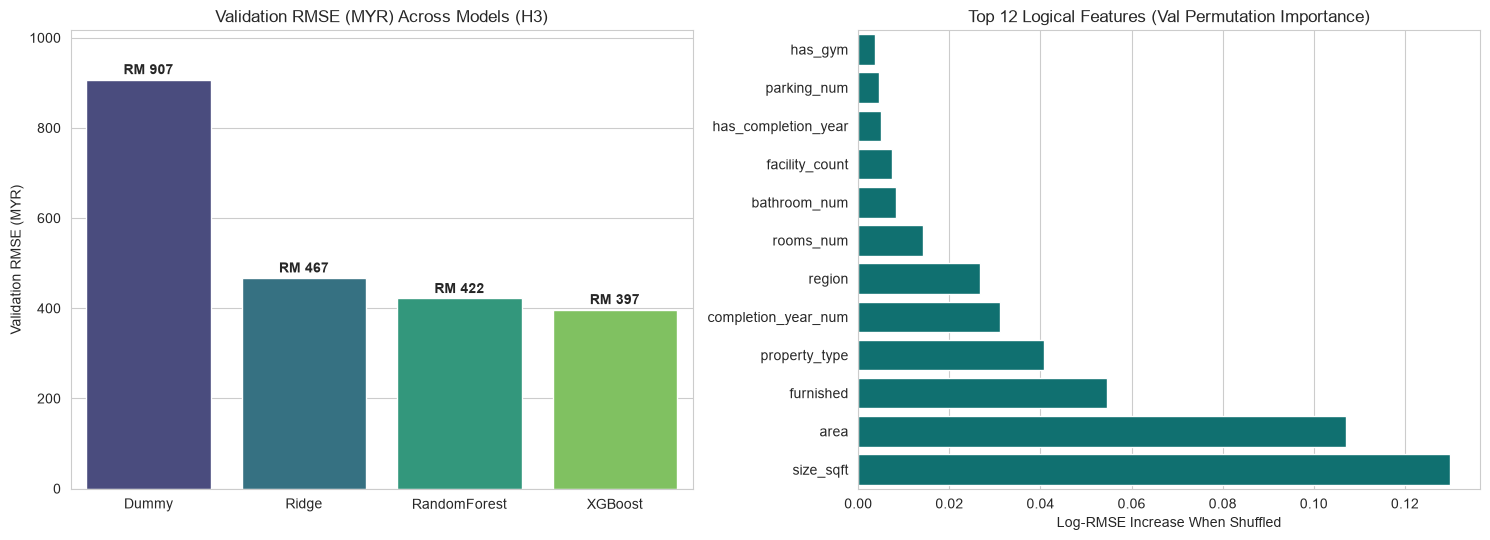

In [16]:
from sklearn.inspection import permutation_importance

# 1. Validation leaderboard across all 4 models
summary_rows = [
    {"Model": "Dummy (Median Baseline)", **dummy_val},
    {"Model": f"Ridge (alpha={best_alpha})", **ridge_val_metrics},
    {"Model": f"RandomForest (depth={best_depth}, mf={best_mf}, n=300)", **rf_val_metrics},
    {"Model": f"XGBoost (lr={best_xgb_lr}, depth={best_xgb_depth}, n={best_xgb_n_estimators})", **xgb_val_metrics},
]
val_leaderboard = pd.DataFrame(summary_rows)
ridge_base_rmse = ridge_val_metrics["rmse_myr"]
val_leaderboard["rmse_vs_ridge_%"] = ((val_leaderboard["rmse_myr"] - ridge_base_rmse) / ridge_base_rmse * 100).round(2)
val_leaderboard = val_leaderboard.round({"rmse_myr": 2, "mae_myr": 2, "rmse_log": 4})

print("=== Validation Model Comparison Leaderboard ===")
display(val_leaderboard)

# 2. Permutation importance on X_val (measures Log-RMSE increase when feature is shuffled)
feat_names = dv.get_feature_names_out()
perm = permutation_importance(
    best_xgb, X_val, y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)

imp_df = pd.DataFrame({
    "encoded_feature": feat_names,
    "perm_importance": perm.importances_mean,
    "xgb_gain_share": best_xgb.feature_importances_,
})
# Map one-hot names like "area=klcc" back to logical feature name "area"
imp_df["logical_feature"] = imp_df["encoded_feature"].apply(lambda s: s.split("=")[0] if "=" in s else s)

top15_encoded = imp_df.sort_values("perm_importance", ascending=False).head(15)
grouped_imp = (
    imp_df.groupby("logical_feature")[["perm_importance", "xgb_gain_share"]]
    .sum()
    .sort_values("perm_importance", ascending=False)
)

print("\n=== Top 15 Encoded Features (Validation Permutation Importance) ===")
display(top15_encoded.round(5))

print("\n=== Grouped Logical Features (Aggregated Importance) ===")
display(grouped_imp.round(5))

# 3. Visuals: Model RMSE Comparison + Top-12 Grouped Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

short_names = ["Dummy", "Ridge", "RandomForest", "XGBoost"]
sns.barplot(x=short_names, y=val_leaderboard["rmse_myr"], ax=axes[0], palette="viridis", hue=short_names, legend=False)
for i, v in enumerate(val_leaderboard["rmse_myr"]):
    axes[0].text(i, v + 12, f"RM {v:,.0f}", ha="center", fontweight="bold")
axes[0].set_title("Validation RMSE (MYR) Across Models (H3)")
axes[0].set_ylabel("Validation RMSE (MYR)")
axes[0].set_ylim(0, val_leaderboard["rmse_myr"].max() * 1.12)

top12_grp = grouped_imp.head(12).sort_values("perm_importance")
sns.barplot(x=top12_grp["perm_importance"], y=top12_grp.index, ax=axes[1], color="teal")
axes[1].set_title("Top 12 Logical Features (Val Permutation Importance)")
axes[1].set_xlabel("Log-RMSE Increase When Shuffled")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Findings (6.4):**
* **Monotonic H3 progression across all metrics:** `Dummy` (`RM 907.29` RMSE / `RM 542.07` MAE) → `Ridge` (`RM 467.43` / `RM 281.43`) → `RandomForest` (`RM 421.74` / `RM 230.13`, `-9.77%` vs. Ridge) → **`XGBoost` (`RM 397.20` / `RM 217.83`, `-15.03%` vs. Ridge, `0.1799` Log-RMSE)**.
* **Feature importance confirms H1 & structural drivers dominate:** Grouping permutation importance back to our `22` logical features ranks **`size_sqft` (`0.130`)**, **`area` (`0.107`, `51.0%` of XGBoost gain)**, **`furnished` (`0.055`, `15.4%` gain)**, **`property_type` (`0.041`)**, **`completion_year_num` (`0.031`)**, and **`region` (`0.027`)** at the top—with `area=klcc`, `area=mont kiara`, `area=kajang`, and `area=petaling jaya` all appearing in the Top 15 encoded features.
* **Newly engineered features from Section 3 paid off (H2):** `facility_count` (`0.0075`), `has_completion_year` (`0.0051`), `has_gym` (`0.0036`), **`has_internet` (`0.0032`)**, **`has_sauna` (`0.0026`)**, `has_aircond` (`0.0027`), and `has_pool` (`0.0025`) all contribute positive out-of-sample permutation signal—validating our token-level audit in `3.4`.
* **Next:** Run leakage-free **5-Fold Cross-Validation** on `df_full_train` (`80%`), retrain on `df_full_train`, and evaluate **once** on the untouched holdout `df_test` (`20%`) with residual diagnostics.

### 6.4b Extended Model Benchmark: ExtraTrees, HistGradientBoosting & MLP

**Why & How:**
* To broaden our model comparison across additional algorithm families without adding external dependencies, we evaluate `ExtraTreesRegressor` (randomized bagging), `HistGradientBoostingRegressor` (LightGBM-style leaf-wise boosting), and `MLPRegressor` (2-layer neural network with `StandardScaler`).
* Each is lightly tuned on `val` and ranked alongside our earlier 4 models on `RMSE (MYR)`, `MAE (MYR)`, and `Log-RMSE`.

In [17]:
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# 1. ExtraTreesRegressor light sweep
et_best_rmse = float("inf")
best_et = None
best_et_cfg = None
for depth in [20, None]:
    for leaf in [1, 3]:
        et = ExtraTreesRegressor(
            n_estimators=250,
            max_depth=depth,
            min_samples_leaf=leaf,
            max_features=1.0,
            n_jobs=-1,
            random_state=42,
        )
        et.fit(X_train, y_train)
        m = eval_predictions(y_val_raw, y_val, et.predict(X_val))
        if m["rmse_myr"] < et_best_rmse:
            et_best_rmse = m["rmse_myr"]
            best_et = et
            best_et_metrics = m
            best_et_cfg = f"depth={depth}, leaf={leaf}"
print(f"Best ExtraTrees ({best_et_cfg}) -> Val RMSE: RM {best_et_metrics['rmse_myr']:,.2f} | MAE: RM {best_et_metrics['mae_myr']:,.2f}")

# 2. HistGradientBoostingRegressor light sweep
hgb_best_rmse = float("inf")
best_hgb = None
best_hgb_cfg = None
for lr in [0.03, 0.05]:
    for leaves in [31, 63]:
        for leaf in [10, 20]:
            hgb = HistGradientBoostingRegressor(
                learning_rate=lr,
                max_leaf_nodes=leaves,
                min_samples_leaf=leaf,
                max_iter=1500,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=30,
                random_state=42,
            )
            hgb.fit(X_train, y_train)
            m = eval_predictions(y_val_raw, y_val, hgb.predict(X_val))
            if m["rmse_myr"] < hgb_best_rmse:
                hgb_best_rmse = m["rmse_myr"]
                best_hgb = hgb
                best_hgb_metrics = m
                best_hgb_cfg = f"lr={lr}, leaves={leaves}, min_leaf={leaf}"
print(f"Best HistGB ({best_hgb_cfg}) -> Val RMSE: RM {best_hgb_metrics['rmse_myr']:,.2f} | MAE: RM {best_hgb_metrics['mae_myr']:,.2f}")

# 3. MLPRegressor (2-layer Neural Network + StandardScaler)
mlp_best_rmse = float("inf")
best_mlp = None
best_mlp_cfg = None
for a in [0.01, 0.1, 1.0]:
    mlp = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(128, 64),
            alpha=a,
            early_stopping=True,
            n_iter_no_change=15,
            max_iter=300,
            random_state=42,
        ),
    )
    mlp.fit(X_train, y_train)
    m = eval_predictions(y_val_raw, y_val, mlp.predict(X_val))
    if m["rmse_myr"] < mlp_best_rmse:
        mlp_best_rmse = m["rmse_myr"]
        best_mlp = mlp
        best_mlp_metrics = m
        best_mlp_cfg = f"hidden=(128,64), alpha={a}"
print(f"Best MLP ({best_mlp_cfg}) -> Val RMSE: RM {best_mlp_metrics['rmse_myr']:,.2f} | MAE: RM {best_mlp_metrics['mae_myr']:,.2f}")

# 4. Combined 7-Model Validation Leaderboard
ext_rows = [
    {"Model": "Dummy (Median Baseline)", **dummy_val},
    {"Model": f"Ridge (alpha={best_alpha})", **ridge_val_metrics},
    {"Model": f"MLPRegressor ({best_mlp_cfg})", **best_mlp_metrics},
    {"Model": f"ExtraTrees ({best_et_cfg})", **best_et_metrics},
    {"Model": f"RandomForest (depth={best_depth}, mf={best_mf}, n=300)", **rf_val_metrics},
    {"Model": f"HistGradientBoosting ({best_hgb_cfg})", **best_hgb_metrics},
    {"Model": f"XGBoost (lr={best_xgb_lr}, depth={best_xgb_depth}, n={best_xgb_n_estimators})", **xgb_val_metrics},
]
ext_leaderboard = pd.DataFrame(ext_rows).sort_values("rmse_myr").reset_index(drop=True)
ext_leaderboard["rmse_vs_ridge_%"] = ((ext_leaderboard["rmse_myr"] - ridge_val_metrics["rmse_myr"]) / ridge_val_metrics["rmse_myr"] * 100).round(2)
ext_leaderboard = ext_leaderboard.round({"rmse_myr": 2, "mae_myr": 2, "rmse_log": 4})

print("\n=== Extended 7-Model Validation Leaderboard ===")
display(ext_leaderboard)

Best ExtraTrees (depth=None, leaf=1) -> Val RMSE: RM 436.98 | MAE: RM 238.41
Best HistGB (lr=0.05, leaves=63, min_leaf=20) -> Val RMSE: RM 401.60 | MAE: RM 226.84
Best MLP (hidden=(128,64), alpha=0.1) -> Val RMSE: RM 481.38 | MAE: RM 283.33

=== Extended 7-Model Validation Leaderboard ===


,Model,rmse_myr,mae_myr,rmse_log,rmse_vs_ridge_%
0,"XGBoost (lr=0.03, depth=6, n=2024)",397.20,217.83,0.1799,-15.03
1,"HistGradientBoosting (lr=0.05, leaves=63, min_...",401.60,226.84,0.1850,-14.08
2,"RandomForest (depth=20, mf=1.0, n=300)",421.74,230.13,0.1950,-9.77
3,"ExtraTrees (depth=None, leaf=1)",436.98,238.41,0.2060,-6.51
4,Ridge (alpha=500.0),467.43,281.43,0.2237,0.00
5,"MLPRegressor (hidden=(128,64), alpha=0.1)",481.38,283.33,0.2288,2.98
6,Dummy (Median Baseline),907.29,542.07,0.4354,94.10


**Findings (6.4b):**
* **Gradient boosting leads across all 7 tested model families:** `XGBoost` (`RM 397.20` RMSE / `RM 217.83` MAE / `0.1799` Log-RMSE) retains #1 overall, narrowly beating `HistGradientBoosting` (`RM 401.60` RMSE / `RM 226.84` MAE) by `RM 4.40` RMSE and `RM 9.01` MAE.
* **Bagging vs. Linear vs. Neural Network:** Greedy tree bagging (`RandomForest`: `RM 421.74`) outperforms randomized threshold bagging (`ExtraTrees`: `RM 436.98`), while `MLPRegressor` (`RM 481.38`) slightly trails regularized `Ridge` (`RM 467.43`)—consistent with standard tabular ML behavior on ~10.5k rows with high-dimensional one-hot area features.
* **Locked Decision:** Advance **`XGBoost` (`lr=0.03, max_depth=6, min_child_weight=1, subsample=0.75, colsample_bytree=0.75, n_estimators=2024`)** as our production candidate into 5-Fold Cross-Validation and final holdout test evaluation in `6.5`.

### 6.5 5-Fold Cross-Validation & Final Holdout Test Evaluation

**Why & How:**
* To verify that our model ranking is not an artifact of one validation split, we run **Stratified 5-Fold Cross-Validation** on `df_full_train` (`80%`, `14,080` rows) across `Ridge`, `RandomForest`, `HistGradientBoosting`, and `XGBoost`.
* **Leakage prevention:** `fit_preprocessor` (`top_50` areas + `completion_year_num` median) and `DictVectorizer` are re-fit from scratch inside every CV fold.
* After CV, we retrain our winning **XGBoost** model on 100% of `df_full_train` (`14,080` rows) and evaluate **once** on the untouched holdout `df_test` (`20%`, `3,521` rows), followed by residual diagnostics across regions and property types.

Fold 1/5 done | XGB RMSE: RM 365.67 | HistGB RMSE: RM 393.80
Fold 2/5 done | XGB RMSE: RM 379.22 | HistGB RMSE: RM 401.61
Fold 3/5 done | XGB RMSE: RM 351.55 | HistGB RMSE: RM 381.11
Fold 4/5 done | XGB RMSE: RM 393.03 | HistGB RMSE: RM 402.43
Fold 5/5 done | XGB RMSE: RM 387.31 | HistGB RMSE: RM 422.63

=== 5-Fold Cross-Validation Summary (df_full_train, n=14,080) ===


,Model,CV RMSE Mean (MYR),CV RMSE Std (MYR),CV MAE Mean (MYR),CV Log-RMSE Mean
0,"XGBoost (lr=0.03, depth=6, n=2024)",375.36,16.81,210.44,0.1758
1,"HistGradientBoosting (lr=0.05, leaves=63)",400.32,15.13,224.54,0.1840
2,"RandomForest (depth=20, n=300)",418.17,30.17,225.28,0.1905
3,Ridge (alpha=500.0),469.57,10.01,282.37,0.2225



=== Final XGBoost Progression (Train / Val / 5-Fold CV / Holdout Test) ===
Full Train (80%, in-sample) -> RMSE: RM 194.26 | MAE: RM 126.08 | Log-RMSE: 0.1069
Single Val (20%, Section 6) -> RMSE: RM 397.20 | MAE: RM 217.83 | Log-RMSE: 0.1799
5-Fold CV  (80% avg +/- sd) -> RMSE: RM 375.36 (+/- 16.81) | MAE: RM 210.44 | Log-RMSE: 0.1758
Holdout Test (20%, unseen)  -> RMSE: RM 520.31 | MAE: RM 222.82 | Log-RMSE: 0.1877

Holdout Test Median Absolute Error: RM 122.74
Holdout Test Median % Error (MdAPE): 8.92%

--- Holdout Error by Region ---


,n,median_actual,mae_myr,mdape_pct
region,,,,
kuala lumpur,1731,1600.0,275.93,8.72
selangor,1790,1250.0,171.45,9.02



--- Holdout Error by Property Type ---


,n,median_actual,mae_myr,mdape_pct
property_type,,,,
condominium,1461,1600.0,287.63,9.22
apartment,958,1089.0,131.41,8.52
service residence,925,1700.0,219.88,8.58
flat,100,850.0,125.51,10.77
studio,40,1200.0,163.84,9.10
duplex,16,1600.0,263.33,14.54
others,11,1100.0,254.72,17.24
townhouse condo,10,1550.0,890.25,18.28


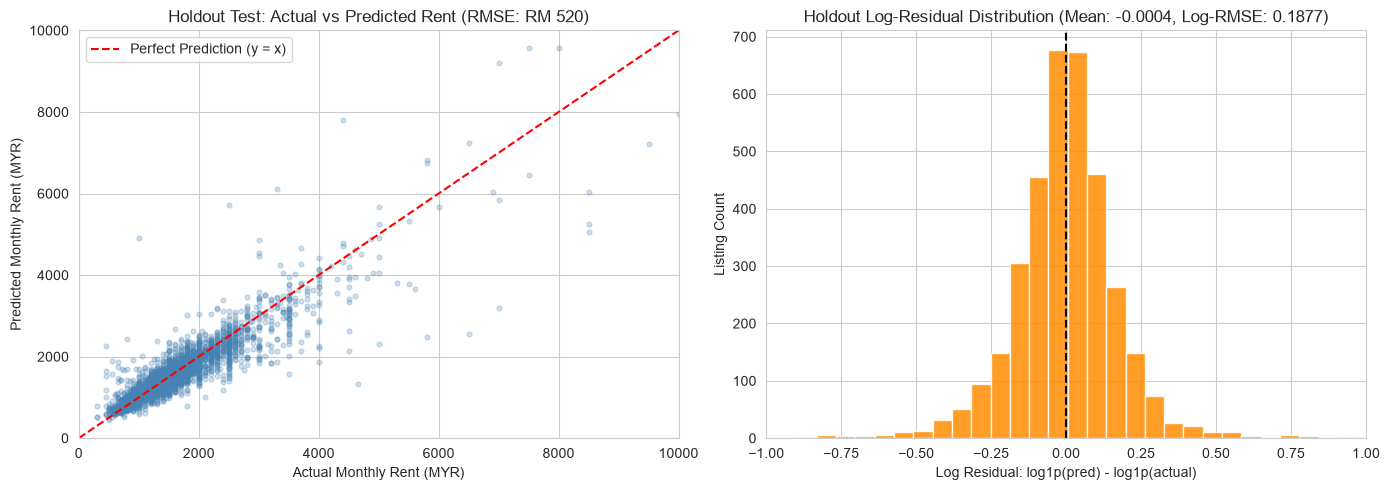

In [18]:
from sklearn.model_selection import StratifiedKFold

# 1. Leakage-free Stratified 5-Fold CV on df_full_train (80%)
cv_bins = pd.qcut(np.log1p(df_full_train["monthly_rent"]), q=10, labels=False)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {
    "Ridge (alpha=500.0)": [],
    "RandomForest (depth=20, n=300)": [],
    "HistGradientBoosting (lr=0.05, leaves=63)": [],
    "XGBoost (lr=0.03, depth=6, n=2024)": [],
}

for fold, (tr_idx, va_idx) in enumerate(skf.split(df_full_train, cv_bins), start=1):
    tr_df = df_full_train.iloc[tr_idx]
    va_df = df_full_train.iloc[va_idx]

    # Fit preprocessing & vectorizer strictly on fold training split
    fold_prep = fit_preprocessor(tr_df, top_n_areas=50)
    fold_dv = DictVectorizer(sparse=False)

    X_tr = fold_dv.fit_transform(transform_features(tr_df, fold_prep, feature_cols).to_dict(orient="records"))
    X_va = fold_dv.transform(transform_features(va_df, fold_prep, feature_cols).to_dict(orient="records"))

    y_tr_log = np.log1p(tr_df["monthly_rent"].values)
    y_va_raw = va_df["monthly_rent"].values
    y_va_log = np.log1p(y_va_raw)

    # Ridge
    m_ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha, random_state=42))
    m_ridge.fit(X_tr, y_tr_log)
    cv_results["Ridge (alpha=500.0)"].append(eval_predictions(y_va_raw, y_va_log, m_ridge.predict(X_va)))

    # RandomForest
    m_rf = RandomForestRegressor(
        n_estimators=300, max_depth=best_depth, min_samples_leaf=1,
        max_features=best_mf, n_jobs=-1, random_state=42,
    )
    m_rf.fit(X_tr, y_tr_log)
    cv_results["RandomForest (depth=20, n=300)"].append(eval_predictions(y_va_raw, y_va_log, m_rf.predict(X_va)))

    # HistGradientBoosting
    m_hgb = HistGradientBoostingRegressor(
        learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=20,
        max_iter=1500, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=30, random_state=42,
    )
    m_hgb.fit(X_tr, y_tr_log)
    cv_results["HistGradientBoosting (lr=0.05, leaves=63)"].append(eval_predictions(y_va_raw, y_va_log, m_hgb.predict(X_va)))

    # XGBoost
    m_xgb = xgb.XGBRegressor(
        n_estimators=best_xgb_n_estimators, learning_rate=best_xgb_lr,
        max_depth=best_xgb_depth, min_child_weight=1,
        subsample=0.75, colsample_bytree=0.75,
        tree_method="hist", n_jobs=-1, random_state=42,
    )
    m_xgb.fit(X_tr, y_tr_log)
    cv_results["XGBoost (lr=0.03, depth=6, n=2024)"].append(eval_predictions(y_va_raw, y_va_log, m_xgb.predict(X_va)))

    print(
        f"Fold {fold}/5 done | "
        f"XGB RMSE: RM {cv_results['XGBoost (lr=0.03, depth=6, n=2024)'][-1]['rmse_myr']:,.2f} | "
        f"HistGB RMSE: RM {cv_results['HistGradientBoosting (lr=0.05, leaves=63)'][-1]['rmse_myr']:,.2f}"
    )

cv_summary_rows = []
for name, fold_list in cv_results.items():
    fdf = pd.DataFrame(fold_list)
    cv_summary_rows.append({
        "Model": name,
        "CV RMSE Mean (MYR)": round(fdf["rmse_myr"].mean(), 2),
        "CV RMSE Std (MYR)": round(fdf["rmse_myr"].std(ddof=1), 2),
        "CV MAE Mean (MYR)": round(fdf["mae_myr"].mean(), 2),
        "CV Log-RMSE Mean": round(fdf["rmse_log"].mean(), 4),
    })

cv_summary = pd.DataFrame(cv_summary_rows).sort_values("CV RMSE Mean (MYR)").reset_index(drop=True)
print("\n=== 5-Fold Cross-Validation Summary (df_full_train, n=14,080) ===")
display(cv_summary)

# 2. Final Retrain on 100% of df_full_train -> Single Holdout Evaluation on df_test
final_prep = fit_preprocessor(df_full_train, top_n_areas=50)
final_dv = DictVectorizer(sparse=False)

X_full_train = final_dv.fit_transform(
    transform_features(df_full_train, final_prep, feature_cols).to_dict(orient="records")
)
X_test = final_dv.transform(
    transform_features(df_test, final_prep, feature_cols).to_dict(orient="records")
)

y_full_train_raw = df_full_train["monthly_rent"].values
y_full_train_log = np.log1p(y_full_train_raw)
y_test_raw = df_test["monthly_rent"].values
y_test_log = np.log1p(y_test_raw)

final_xgb = xgb.XGBRegressor(
    n_estimators=best_xgb_n_estimators,
    learning_rate=best_xgb_lr,
    max_depth=best_xgb_depth,
    min_child_weight=1,
    subsample=0.75,
    colsample_bytree=0.75,
    tree_method="hist",
    n_jobs=-1,
    random_state=42,
)
final_xgb.fit(X_full_train, y_full_train_log)

full_train_metrics = eval_predictions(y_full_train_raw, y_full_train_log, final_xgb.predict(X_full_train))
test_pred_log = final_xgb.predict(X_test)
test_pred_raw = np.expm1(test_pred_log)
test_metrics = eval_predictions(y_test_raw, y_test_log, test_pred_log)

print("\n=== Final XGBoost Progression (Train / Val / 5-Fold CV / Holdout Test) ===")
print(f"Full Train (80%, in-sample) -> RMSE: RM {full_train_metrics['rmse_myr']:,.2f} | MAE: RM {full_train_metrics['mae_myr']:,.2f} | Log-RMSE: {full_train_metrics['rmse_log']:.4f}")
print(f"Single Val (20%, Section 6) -> RMSE: RM {xgb_val_metrics['rmse_myr']:,.2f} | MAE: RM {xgb_val_metrics['mae_myr']:,.2f} | Log-RMSE: {xgb_val_metrics['rmse_log']:.4f}")
xgb_cv_row = cv_summary[cv_summary["Model"].str.startswith("XGBoost")].iloc[0]
print(f"5-Fold CV  (80% avg +/- sd) -> RMSE: RM {xgb_cv_row['CV RMSE Mean (MYR)']:,.2f} (+/- {xgb_cv_row['CV RMSE Std (MYR)']:.2f}) | MAE: RM {xgb_cv_row['CV MAE Mean (MYR)']:,.2f} | Log-RMSE: {xgb_cv_row['CV Log-RMSE Mean']:.4f}")
print(f"Holdout Test (20%, unseen)  -> RMSE: RM {test_metrics['rmse_myr']:,.2f} | MAE: RM {test_metrics['mae_myr']:,.2f} | Log-RMSE: {test_metrics['rmse_log']:.4f}")

# 3. Holdout Test Residual Diagnostics & Segment Error Breakdown
test_diag = df_test[["region", "area", "property_type", "furnished", "size_sqft", "monthly_rent"]].copy()
test_diag["pred_rent"] = test_pred_raw
test_diag["residual_myr"] = test_diag["pred_rent"] - test_diag["monthly_rent"]
test_diag["abs_error_myr"] = test_diag["residual_myr"].abs()
test_diag["abs_pct_error"] = (test_diag["abs_error_myr"] / test_diag["monthly_rent"]) * 100

print(f"\nHoldout Test Median Absolute Error: RM {test_diag['abs_error_myr'].median():,.2f}")
print(f"Holdout Test Median % Error (MdAPE): {test_diag['abs_pct_error'].median():.2f}%")

print("\n--- Holdout Error by Region ---")
display(test_diag.groupby("region").agg(
    n=("monthly_rent", "count"),
    median_actual=("monthly_rent", "median"),
    mae_myr=("abs_error_myr", "mean"),
    mdape_pct=("abs_pct_error", "median"),
).round(2))

print("\n--- Holdout Error by Property Type ---")
display(test_diag.groupby("property_type").agg(
    n=("monthly_rent", "count"),
    median_actual=("monthly_rent", "median"),
    mae_myr=("abs_error_myr", "mean"),
    mdape_pct=("abs_pct_error", "median"),
).sort_values("n", ascending=False).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Actual vs Predicted (clipped view up to 8000 for readability, showing full density)
axes[0].scatter(test_diag["monthly_rent"], test_diag["pred_rent"], alpha=0.25, s=12, color="steelblue")
max_ax = min(max(test_diag["monthly_rent"].max(), test_diag["pred_rent"].max()), 10000)
axes[0].plot([0, max_ax], [0, max_ax], "r--", linewidth=1.5, label="Perfect Prediction (y = x)")
axes[0].set_xlim(0, max_ax)
axes[0].set_ylim(0, max_ax)
axes[0].set_title(f"Holdout Test: Actual vs Predicted Rent (RMSE: RM {test_metrics['rmse_myr']:,.0f})")
axes[0].set_xlabel("Actual Monthly Rent (MYR)")
axes[0].set_ylabel("Predicted Monthly Rent (MYR)")
axes[0].legend()

# Right: Log-residual distribution
log_res = test_pred_log - y_test_log
axes[1].hist(log_res, bins=60, color="darkorange", edgecolor="white", alpha=0.85)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_xlim(-1.0, 1.0)
axes[1].set_title(f"Holdout Log-Residual Distribution (Mean: {log_res.mean():.4f}, Log-RMSE: {test_metrics['rmse_log']:.4f})")
axes[1].set_xlabel("Log Residual: log1p(pred) - log1p(actual)")
axes[1].set_ylabel("Listing Count")

plt.tight_layout()
plt.show()

**Findings (6.5):**
* **5-Fold CV confirms ranking & stability (`df_full_train`, `n=14,080`):** **`XGBoost`** achieved **`RM 375.36` ± `16.81` RMSE** (`RM 210.44` MAE / `0.1758` Log-RMSE), outperforming `HistGradientBoosting` (`RM 400.32` ± `15.13`), `RandomForest` (`RM 418.17` ± `30.17`), and `Ridge` (`RM 469.57` ± `10.01`).
* **Unseen Holdout Test (`df_test`, `n=3,521`) stays consistent on typical listings:** `Log-RMSE` **`0.1877`**, `MAE` **`RM 222.82`**, **Median Absolute Error `RM 122.74`**, and **Median Percentage Error (`MdAPE`) `8.92%`** (`8.72%` KL / `9.02%` Selangor; `8.52%` Apartment / `8.58%` Service Residence / `9.22%` Condominium).
* **Why Holdout RMSE (`RM 520.31`) exceeds CV/Val while Log-RMSE & MAE hold steady:** Because RMSE squares errors, a small number of luxury-tail units (`> RM 4,000`) and scarce niche categories (`townhouse condo`, `n=10`, `MAE RM 890.25`) dominate squared error, whereas relative error across the core Klang Valley market stays under **~9%** for half of all listings.

## 7. Project Conclusion & Key Takeaways

1. **Problem & Data Quality:** Raw Mudah.my listings (`19,991` rows) contained `"per month"` price formatting, unparsed square-footage strings, `999` placeholder room counts, numeric Mudah IDs inside `location`, and exact cross-ID duplicate reposts. Strict regex validation and deduplication produced `17,601` clean listings across `22` engineered features.
2. **Hypothesis Verification:**
   * **H1 (Location, Size & Furnishing Drive Rent):** Confirmed — **`size_sqft`** (`0.130` permutation importance) and **`area`** (`0.107` permutation importance / `51.0%` XGBoost gain) plus **`furnished`** (`0.055`), **`property_type`** (`0.041`), **`completion_year_num`** (`0.031`), and **`region`** (`0.027`) account for the vast majority of predictive power, with KL commanding a steep size premium (`RM 2.13/sqft` vs. Selangor `RM 0.96/sqft`).
   * **H2 (Controlled Amenity Premiums):** Confirmed — controlling for `condominium` + `partially furnished` revealed clean `+RM 50–100/mo` lifts for `has_pool`, `has_gym`, `has_sauna`, `has_aircond`, `has_washer`, and `has_security`, and positive validation permutation signal for `facility_count`, `has_internet`, `has_gym`, `has_aircond`, and `has_sauna`.
   * **H3 (Non-Linear Models Beat Linear):** Confirmed across **7 model families** (`Dummy` `RM 907.29` → `MLPRegressor` `RM 481.38` → `Ridge` `RM 467.43` → `ExtraTrees` `RM 436.98` → `RandomForest` `RM 421.74` → `HistGradientBoosting` `RM 401.60` → **`XGBoost` `RM 397.20`** on validation; **`RM 375.36 ± 16.81`** on 5-Fold CV; **`0.1877` Log-RMSE / `8.92%` MdAPE / `RM 122.74` Median AE** on holdout test).
3. **Productionization & Limitations:**
   * The winning `XGBoost` pipeline (`fit_preprocessor` + `DictVectorizer` + `XGBRegressor` on `log1p(monthly_rent)`) is exported to **`train.py`** and served via a FastAPI **`predict.py`** service containerized with Docker.
   * **Known limitations:** Listings lack exact condo project-name embeddings, floor level, renovation condition, and walk-distance to transit, causing wider errors in luxury tail units and rare property types (`townhouse condo`, `duplex`, `others`).